<a href="https://colab.research.google.com/github/dherreraal/object_oriented_programming/blob/main/Clase_12/12_POO_Arrays_Matrices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Arreglos y Matrices en Java: Vectores Unidimensionales y Matrices Bidimensionales
### Universidad Nacional de Colombia
#### **Profesor:** David Alberto Herrera Alvarez
#### **Curso:** Programación Orientada a Objetos
---


## Índice de Contenido
1. Introducción al Concepto de Arreglo (Array) y su Modelo en Memoria
2. Declaración, Creación e Inicialización de Arreglos Unidimensionales (1D)
3. Indexación, Límites e Inmutabilidad de `.length`
4. Estrategias de Recorrido: Bucle Tradicional `for` vs. `for-each` (Enhanced For)
5. Algoritmos Fundamentales sobre Vectores:
   - 5.1 Inversión de Elementos usando Dos Punteros (*Two-Pointer Approach*)
   - 5.2 Búsquedas: Búsqueda Lineal vs. Búsqueda Binaria (*Binary Search*)
   - 5.3 Ordenamiento Básico: Método de la Burbuja Optimizado (*Bubble Sort*)
6. Arreglos de Referencias a Objetos (POO) y Evitación de `NullPointerException`
7. Matrices Bidimensionales (2D): La Arquitectura "Arreglo de Arreglos"
8. Patrones de Recorrido y Operaciones Matriciales (Diagonales, Transpuesta y Simetría)
9. Arreglos Irregulares o Escalonados (*Jagged / Ragged Arrays*)
10. Buenas Prácticas y Errores Frecuentes (*Pitfalls*)
11. Ejercicios Prácticos
12. Bibliografía y Referencias
---

## 1. Introducción a los Arreglos y su Modelo en Memoria

En programación, un **arreglo** (*array*) es una de las estructuras de datos fundamentales más utilizadas. Formalmente, un arreglo es una colección contigua y de tamaño fijo de elementos homogéneos (es decir, todos pertenecen exactamente al mismo tipo de dato, ya sea un tipo primitivo como `int`, `double` o `boolean`, o un tipo por referencia como `String` o cualquier clase personalizada).

### Características Fundamentales
1. **Homogeneidad:** Todos los elementos comparten el mismo tipo de dato declarado.
2. **Tamaño Fijo e Inmutable:** Una vez que un arreglo es instanciado en tiempo de ejecución, su capacidad no puede crecer ni encogerse. Si se requieren más posiciones, es obligatorio reservar un nuevo arreglo en memoria y copiar los elementos.
3. **Acceso Aleatorio $O(1)$:** Debido a que los elementos residen en direcciones contiguas de memoria física, la dirección de cualquier elemento $i$ se calcula directamente mediante una fórmula aritmética simple:
   $$\text{Dirección}(A[i]) = \text{Dirección Base} + i \times \text{Tamaño en bytes del tipo de dato}$$
   Esto permite que leer o escribir en la posición $0$, $50$ o $1\,000\,000$ tome exactamente el mismo tiempo constante.
4. **Tratamiento como Objetos en Java:** A diferencia de lenguajes como C o C++ donde un arreglo es un puntero directo a memoria sin metadatos asociados, en Java **todo arreglo es un objeto de primera clase** que reside en la memoria dinámica (*Heap*), cuenta con una variable miembro constante pública llamada `.length`, hereda directamente de `java.lang.Object` y está protegido por verificación automática de límites (*Bounds Checking*) realizada por la Máquina Virtual de Java (JVM).

A continuación se ilustra con máxima claridad la separación entre la variable de referencia alojada en el *Stack* y el objeto arreglo residiendo en el *Heap*:

<div align="center">
  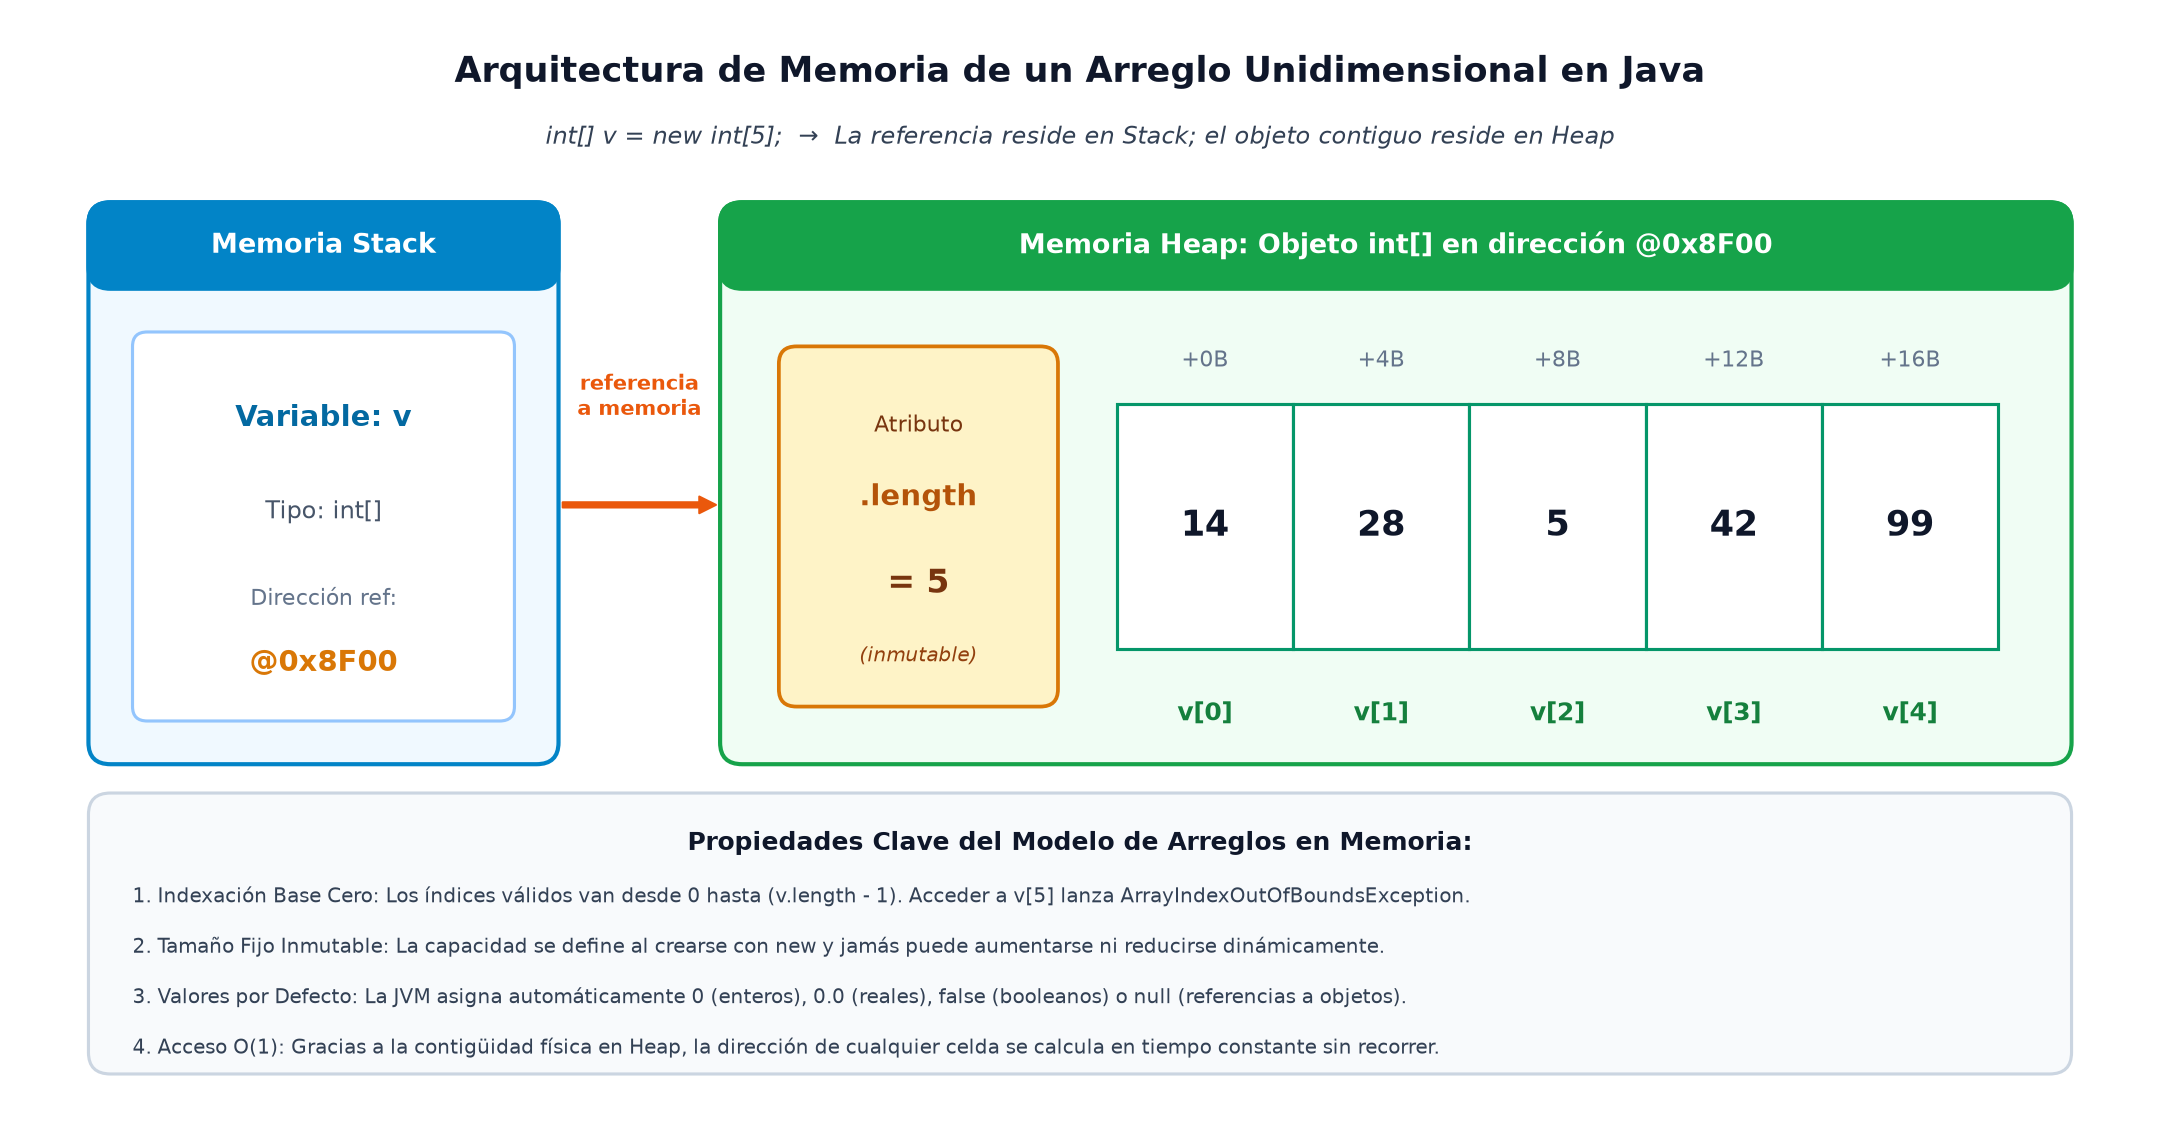
  <p><em>Figura 1: Representación de un arreglo unidimensional en memoria. La variable referencia en el Stack apunta a un bloque contiguo en el Heap que almacena el metadato inmutable <code>length</code> y las celdas indexadas de $0$ a $n-1$.</em></p>
</div>


## 2. Declaración, Creación e Inicialización de Arreglos 1D

El ciclo de vida de un arreglo en Java consta de tres etapas fundamentales: **declaración**, **instanciación** (o reserva de memoria) e **inicialización**.

### 2.1 Declaración
La declaración únicamente crea la variable de referencia en el *Stack*. En este momento, no se reserva ningún espacio para los elementos en el *Heap*, y la referencia contiene `null` (o queda sin inicializar si es una variable local).

```java
// Sintaxis estándar y recomendada en Java (los corchetes van junto al tipo):
int[] temperaturas;
String[] nombres;
double[] calificaciones;

// Sintaxis alterna heredada de C (válida, pero desaconsejada en Java):
int temperaturasC[];
```

> **Regla de Oro:** En la declaración **NUNCA** se especifica el tamaño. Escribir `int[10] arr;` produce un error de compilación inmediato.

---

### 2.2 Creación / Instanciación con `new`
La palabra clave `new` reserva un bloque contiguo de memoria en el *Heap* con la capacidad indicada entre corchetes:

```java
temperaturas = new int[5]; // Se reservan 5 posiciones contiguas de tipo int
```

Al crearse mediante `new`, Java inicializa **automáticamente** cada elemento con el valor por defecto de su tipo de dato:
| Tipo de Elemento | Valor por Defecto de la JVM |
| :--- | :--- |
| Tipos numéricos enteros (`byte`, `short`, `int`, `long`) | `0` |
| Tipos numéricos de punto flotante (`float`, `double`) | `0.0` |
| Tipo booleano (`boolean`) | `false` |
| Tipo carácter (`char`) | `'\u0000'` (carácter nulo) |
| Tipos por referencia (`String`, objetos, arreglos) | `null` |

---

### 2.3 Inicialización Explícita (Shorthand Syntaxes)
Si conocemos los valores desde el momento de la codificación, podemos declarar, instanciar e inicializar en un solo paso:

```java
// 1. Sintaxis abreviada con inicializador literal (solo permitida al declarar):
int[] primos = {2, 3, 5, 7, 11, 13};

// 2. Sintaxis anónima con new (útil para reasignar o pasar como argumento directo a un método):
primos = new int[]{17, 19, 23, 29};

// Pasar arreglo anónimo a un método:
imprimirVector(new double[]{1.5, 3.2, 4.8});
```


## 3. Indexación, Límites e Inmutabilidad de `.length`

### 3.1 Indexación Base Cero (*Zero-based Indexing*)
En Java, los índices de un arreglo de tamaño $N$ van estrictamente desde $0$ hasta $N - 1$:
- Primer elemento: `arr[0]`
- Último elemento: `arr[arr.length - 1]`

### 3.2 La Propiedad `.length`
- Cada objeto arreglo posee un campo público `final` (constante) llamado `length`.
- **Diferencia crítica con Strings y Colecciones:**
  - En un arreglo: es un **atributo** (`arr.length` sin paréntesis).
  - En un `String`: es un **método** (`cadena.length()`).
  - En una colección (`List`, `Set`): es un **método** (`lista.size()`).
- Dado que `length` es `final`, intentar modificarlo (`arr.length = 10;`) genera un error de compilación.

### 3.3 Verificación de Límites en Tiempo de Ejecución (*Bounds Checking*)
Cada acceso `arr[k]` es evaluado por la JVM. Si $k < 0$ o $k \ge \text{arr.length}$, la JVM detiene la ejecución normal y lanza la excepción:
```text
java.lang.ArrayIndexOutOfBoundsException: Index k out of bounds for length N
```
A diferencia de C/C++, donde acceder fuera de los límites provoca lectura o corrupción de memoria aleatoria (*Undefined Behavior*), Java garantiza seguridad de memoria (*Memory Safety*).


## 4. Estrategias de Recorrido: Bucle Tradicional `for` vs. `for-each`

Existen dos maneras idiomáticas de iterar sobre un arreglo en Java:

### 4.1 Bucle Tradicional con Índice (`for`)
Permite conocer y manipular la posición actual $i$. Es indispensable cuando se necesita:
- Modificar los elementos del arreglo.
- Recorrer el arreglo en orden inverso o con saltos mayores a 1.
- Acceder a elementos adyacentes (por ejemplo, comparar `arr[i]` con `arr[i+1]`).
- Controlar múltiples índices simultáneamente (técnica de dos punteros).

```java
int[] valores = {10, 20, 30, 40};
for (int i = 0; i < valores.length; i++) {
    valores[i] *= 2; // Modificación permitida
    System.out.println("Índice " + i + ": " + valores[i]);
}
```

---

### 4.2 Bucle Mejorado (`for-each` / Enhanced For)
Introducido en Java 5, proporciona una sintaxis compacta y legible para recorrer todos los elementos de principio a fin:
- **Solo lectura:** La variable de iteración almacena una copia local del valor del elemento en tipos primitivos. Asignarle un nuevo valor **NO** modifica el arreglo.
- **Sin acceso al índice:** No es posible saber directamente en qué índice se encuentra la iteración.

```java
int suma = 0;
for (int num : valores) {
    suma += num; // Recorrido limpio y seguro contra errores de índice
}
```

| Criterio | Bucle `for` con Índice | Bucle Mejorado `for-each` |
| :--- | :--- | :--- |
| **Acceso al índice** | Sí (`i = 0, 1, ...`) | No |
| **Modificación de primitivos** | Sí (`arr[i] = x`) | No (modifica solo la variable local) |
| **Dirección de recorrido** | Hacia adelante, hacia atrás, con saltos | Estrictamente de izquierda a derecha |
| **Riesgo de `OutOfBounds`** | Posible si la condición del bucle es errónea | Nulo (garantizado por el compilador) |
| **Legibilidad** | Moderada | Máxima |


### Demostración 1: Vectores Unidimensionales en Acción

El siguiente programa ilustra de forma integral:
1. Declaración e instanciación de vectores.
2. Valores por defecto asignados por la JVM.
3. Uso de la constante inmutable `.length`.
4. Comparativa de recorrido entre `for` con índice y `for-each`.
5. Captura y manejo seguro de `ArrayIndexOutOfBoundsException`.



In [1]:
%%writefile DemostracionArreglo1D.java
public class DemostracionArreglo1D {

    public static void main(String[] args) {
        System.out.println("=================================================");
        System.out.println("  DEMOSTRACIÓN 1: VECTORES UNIDIMENSIONALES 1D   ");
        System.out.println("=================================================\n");

        // 1. Comprobación de valores por defecto de la JVM
        int[] enterosPorDefecto = new int[3];
        boolean[] booleanosPorDefecto = new boolean[3];
        String[] referenciasPorDefecto = new String[3];

        System.out.println("--- 1. Valores por Defecto tras new ---");
        System.out.println("int[0]: " + enterosPorDefecto[0]);                  // 0
        System.out.println("boolean[0]: " + booleanosPorDefecto[0]);          // false
        System.out.println("String[0]: " + referenciasPorDefecto[0]);          // null

        // 2. Inicialización explícita y uso de .length
        double[] notas = {4.5, 3.8, 5.0, 4.2, 2.9};
        System.out.println("\n--- 2. Longitud y Acceso a Elementos ---");
        System.out.println("Cantidad de notas (notas.length): " + notas.length);
        System.out.println("Primera nota: " + notas[0]);
        System.out.println("Última nota: " + notas[notas.length - 1]);

        // 3. Modificación mediante bucle tradicional
        System.out.println("\n--- 3. Bucle Tradicional: Modificación de Elementos (+0.5 puntos) ---");
        for (int i = 0; i < notas.length; i++) {
            notas[i] = Math.min(5.0, notas[i] + 0.5); // Bonificación con tope de 5.0
            System.out.printf("  Nota [%d] ajustada: %.2f%n", i, notas[i]);
        }

        // 4. Bucle for-each: Cálculo de promedio (solo lectura)
        System.out.println("\n--- 4. Bucle For-Each: Cálculo de Promedio ---");
        double sumaTotal = 0.0;
        for (double nota : notas) {
            sumaTotal += nota;
        }
        double promedio = sumaTotal / notas.length;
        System.out.printf("Suma total: %.2f | Promedio general: %.2f%n", sumaTotal, promedio);

        // 5. Manejo seguro de ArrayIndexOutOfBoundsException
        System.out.println("\n--- 5. Verificación de Límites (Bounds Checking) ---");
        try {
            System.out.println("Intentando acceder al índice 10...");
            double valorInvalido = notas[10];
            System.out.println("Valor obtenido: " + valorInvalido);
        } catch (ArrayIndexOutOfBoundsException e) {
            System.out.println("CAPTURA EXITOSA: La JVM impidió el acceso inválido.");
            System.out.println("Mensaje de excepción: " + e.getMessage());
        }
    }
}


Writing DemostracionArreglo1D.java


In [2]:
!javac -encoding UTF-8 DemostracionArreglo1D.java
!java DemostracionArreglo1D


[0.025s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.025s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
  DEMOSTRACIÓN 1: VECTORES UNIDIMENSIONALES 1D   

--- 1. Valores por Defecto tras new ---
int[0]: 0
boolean[0]: false
String[0]: null

--- 2. Longitud y Acceso a Elementos ---
Cantidad de notas (notas.length): 5
Primera nota: 4.5
Última nota: 2.9

--- 3. Bucle Tradicional: Modificación de Elementos (+0.5 puntos) ---
  Nota [0] ajustada: 5.

## 5. Algoritmos Fundamentales sobre Vectores

El dominio de los arreglos exige comprender los algoritmos estándar de manipulación, búsqueda y ordenamiento.

### 5.1 Inversión *In-Place* mediante Dos Punteros (*Two-Pointer Approach*)
Invertir un arreglo consiste en permutar los elementos de modo que el primero pase a ser el último, el segundo el penúltimo, etc.
- **Enfoque ingenuo:** Crear un arreglo auxiliar y copiar los elementos de derecha a izquierda. Requiere $O(n)$ memoria adicional.
- **Enfoque óptimo (*In-Place*):** Usar dos índices (punteros conceptuales) `left = 0` y `right = length - 1`. En cada paso, intercambiar `arr[left]` con `arr[right]` mediante una variable temporal `temp`, e incrementar `left` y decrementar `right` hasta que se crucen ($left \ge right$).
  - **Complejidad Temporal:** $O(n/2) = O(n)$
  - **Complejidad Espacial:** $O(1)$ memoria auxiliar.

---

### 5.2 Búsquedas: Búsqueda Lineal vs. Búsqueda Binaria (*Binary Search*)
- **Búsqueda Lineal:** Recorre elemento por elemento secuencialmente de izquierda a derecha. Funciona en arreglos tanto desordenados como ordenados.
  - Complejidad: Peor caso $O(n)$.
- **Búsqueda Binaria:** Requiere **estrictamente** que el arreglo esté ordenado previamente. Compara el elemento buscado con el valor central en `mid = left + (right - left) / 2`:
  - Si coincide, se encontró el índice.
  - Si el objetivo es menor, se descarta toda la mitad derecha (`right = mid - 1`).
  - Si el objetivo es mayor, se descarta toda la mitad izquierda (`left = mid + 1`).
  - Complejidad: Peor caso $O(\log_2 n)$. ¡Para 1 millón de elementos realiza máximo 20 comparaciones!

---

### 5.3 Ordenamiento por Burbuja Optimizado (*Optimized Bubble Sort*)
Compara pares de elementos adyacentes `arr[j]` y `arr[j+1]`, intercambiándolos si están en orden incorrecto. En cada pasada completa, el elemento más grande restante "burbujea" hasta su posición definitiva al final del arreglo.
- **Optimización con bandera:** Si durante una pasada completa no se realiza ningún intercambio (`swapped == false`), el arreglo ya se encuentra completamente ordenado y el algoritmo termina anticipadamente, logrando $O(n)$ en el mejor caso.

A continuación se ilustran ambos algoritmos de manera gráfica:

<div align="center">
  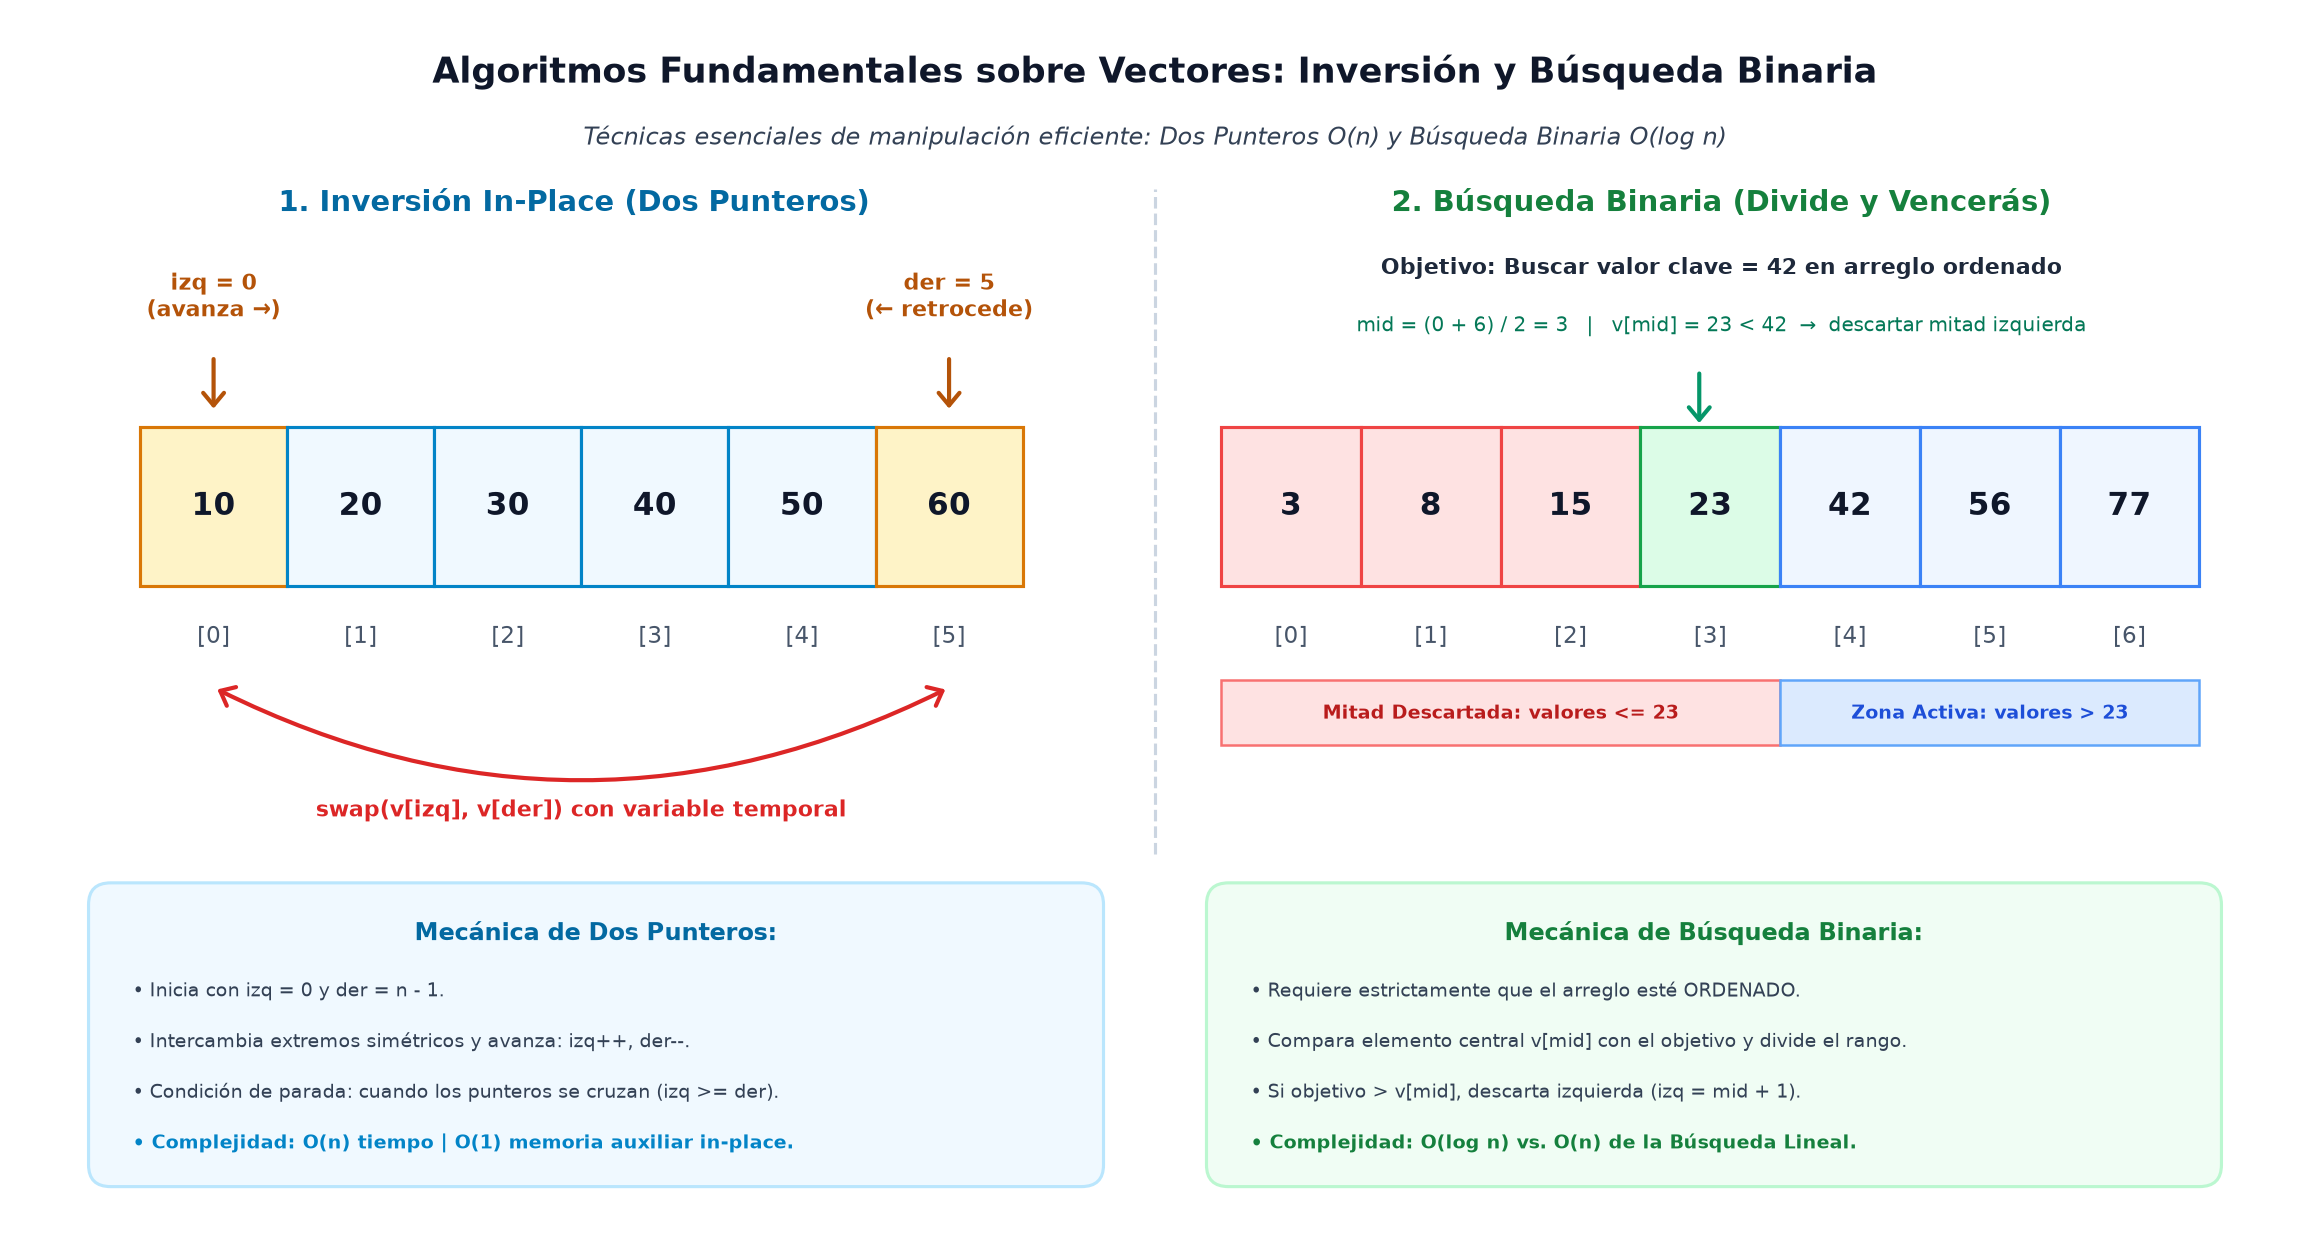
  <p><em>Figura 2: (Izquierda) Algoritmo de dos punteros intercambiando elementos simétricos in-place. (Derecha) Búsqueda binaria descartando la mitad del espacio de búsqueda en cada paso.</em></p>
</div>



### Demostración 2: Algoritmos Fundamentales en Acción

Implementación completa y modular de los algoritmos estudiados: inversión con dos punteros, búsqueda lineal, búsqueda binaria iterativa y ordenamiento burbuja optimizado.



In [3]:
%%writefile DemostracionAlgoritmos1D.java
import java.util.Arrays;

public class DemostracionAlgoritmos1D {

    /**
     * Invierte los elementos de un arreglo in-place usando dos punteros.
     * Complejidad Temporal: O(n) | Espacio Auxiliar: O(1)
     */
    public static void invertirArreglo(int[] arr) {
        int left = 0;
        int right = arr.length - 1;

        while (left < right) {
            // Intercambio (swap) usando variable temporal
            int temp = arr[left];
            arr[left] = arr[right];
            arr[right] = temp;

            left++;
            right--;
        }
    }

    /**
     * Búsqueda lineal: retorna el índice de la primera ocurrencia o -1.
     * Complejidad: O(n)
     */
    public static int busquedaLineal(int[] arr, int objetivo) {
        for (int i = 0; i < arr.length; i++) {
            if (arr[i] == objetivo) {
                return i;
            }
        }
        return -1;
    }

    /**
     * Búsqueda binaria iterativa sobre un arreglo previamente ordenado.
     * Complejidad: O(log n)
     */
    public static int busquedaBinaria(int[] arr, int objetivo) {
        int left = 0;
        int right = arr.length - 1;

        while (left <= right) {
            // Evita desbordamiento aritmético frente a (left + right) / 2
            int mid = left + (right - left) / 2;

            if (arr[mid] == objetivo) {
                return mid; // Elemento encontrado
            } else if (arr[mid] < objetivo) {
                left = mid + 1; // Descartar mitad izquierda
            } else {
                right = mid - 1; // Descartar mitad derecha
            }
        }
        return -1; // No encontrado
    }

    /**
     * Ordenamiento por Burbuja con bandera de optimización temprana.
     * Complejidad: Peor caso O(n^2), Mejor caso O(n)
     */
    public static void bubbleSortOptimizado(int[] arr) {
        int n = arr.length;
        for (int i = 0; i < n - 1; i++) {
            boolean huboIntercambio = false;

            // En cada pasada i, los últimos i elementos ya están colocados
            for (int j = 0; j < n - 1 - i; j++) {
                if (arr[j] > arr[j + 1]) {
                    int temp = arr[j];
                    arr[j] = arr[j + 1];
                    arr[j + 1] = temp;
                    huboIntercambio = true;
                }
            }

            // Si no hubo ningún intercambio, el arreglo ya está ordenado
            if (!huboIntercambio) {
                break;
            }
        }
    }

    public static void main(String[] args) {
        System.out.println("=================================================");
        System.out.println("  DEMOSTRACIÓN 2: ALGORITMOS FUNDAMENTALES 1D    ");
        System.out.println("=================================================\n");

        // 1. Inversión in-place
        int[] datosInvertir = {10, 20, 30, 40, 50, 60};
        System.out.println("Original antes de invertir: " + Arrays.toString(datosInvertir));
        invertirArreglo(datosInvertir);
        System.out.println("Resultado tras invertir:   " + Arrays.toString(datosInvertir));

        // 2. Ordenamiento Burbuja
        int[] desordenado = {64, 34, 25, 12, 22, 11, 90};
        System.out.println("\nOriginal desordenado:      " + Arrays.toString(desordenado));
        bubbleSortOptimizado(desordenado);
        System.out.println("Ordenado con BubbleSort:   " + Arrays.toString(desordenado));

        // 3. Búsqueda Binaria vs Lineal
        int clave = 25;
        int idxBinaria = busquedaBinaria(desordenado, clave);
        System.out.printf("\nBúsqueda Binaria del valor %d en arreglo ordenado -> Índice: %d%n", clave, idxBinaria);

        int claveInexistente = 99;
        int idxNoExiste = busquedaBinaria(desordenado, claveInexistente);
        System.out.printf("Búsqueda Binaria del valor %d (inexistente) -> Índice: %d%n", claveInexistente, idxNoExiste);
    }
}


Writing DemostracionAlgoritmos1D.java


In [4]:
!javac -encoding UTF-8 DemostracionAlgoritmos1D.java
!java DemostracionAlgoritmos1D


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
  DEMOSTRACIÓN 2: ALGORITMOS FUNDAMENTALES 1D    

Original antes de invertir: [10, 20, 30, 40, 50, 60]
Resultado tras invertir:   [60, 50, 40, 30, 20, 10]

Original desordenado:      [64, 34, 25, 12, 22, 11, 90]
Ordenado con BubbleSort:   [11, 12, 22, 25, 34, 64, 90]

Búsqueda Binaria del valor 25 en arreglo ordenado -> Índice: 3
Búsqueda 

## 6. Arreglos de Referencias a Objetos (POO)

En la Programación Orientada a Objetos, es fundamental comprender qué ocurre exactamente al crear un arreglo cuyo tipo de elemento es una clase (por ejemplo, `Estudiante[]` o `CuentaBancaria[]`).

### La Trampa del `NullPointerException`
Cuando ejecutamos:
```java
Estudiante[] curso = new Estudiante[3];
```
**NO se crea ningún objeto `Estudiante`.** En su lugar:
1. Se reserva en el *Heap* un objeto arreglo de longitud 3.
2. Cada una de las 3 celdas es una variable de **referencia** inicializada en `null`.
3. Si intentamos invocar un método inmediatamente, como `curso[0].getNombre()`, la JVM lanzará un fatal `NullPointerException`.

### El Proceso en Dos Fases
Para trabajar correctamente con arreglos de objetos, se deben ejecutar dos pasos de instanciación:
1. **Instanciar el arreglo contenedor:** `Estudiante[] curso = new Estudiante[n];`
2. **Instanciar individualmente cada objeto:** Asignar una instancia concreta creada con `new Estudiante(...)` a cada índice.

```java
// Paso 1: Contenedor de 3 referencias
Estudiante[] curso = new Estudiante[3];

// Paso 2: Instanciación de cada objeto individual
curso[0] = new Estudiante("David Herrera", 4.8);
curso[1] = new Estudiante("Ana Gómez", 4.5);
curso[2] = new Estudiante("Carlos Ruiz", 3.9);
```



### Demostración 3: Arreglos de Objetos y Evitación de `NullPointerException`

El siguiente ejemplo implementa una clase `Estudiante` y muestra el manejo seguro de un arreglo de objetos, la prevención de referencias nulas y el filtrado por atributos.



In [5]:
%%writefile DemostracionArreglosObjetos.java
class Estudiante {
    private String nombre;
    private double promedio;

    public Estudiante(String nombre, double promedio) {
        this.nombre = nombre;
        this.promedio = promedio;
    }

    public String getNombre() {
        return nombre;
    }

    public double getPromedio() {
        return promedio;
    }

    @Override
    public String toString() {
        return String.format("Estudiante{nombre='%s', promedio=%.2f}", nombre, promedio);
    }
}

public class DemostracionArreglosObjetos {

    public static void main(String[] args) {
        System.out.println("=================================================");
        System.out.println("  DEMOSTRACIÓN 3: ARREGLOS DE OBJETOS EN JAVA    ");
        System.out.println("=================================================\n");

        // 1. Instanciación del contenedor (todas las celdas inician en null)
        Estudiante[] curso = new Estudiante[4];
        System.out.println("--- 1. Estado inicial del arreglo de referencias ---");
        for (int i = 0; i < curso.length; i++) {
            System.out.println("curso[" + i + "] = " + curso[i]); // Muestra null
        }

        // 2. Demostración del peligro de NullPointerException
        System.out.println("\n--- 2. Demostración de NullPointerException controlado ---");
        try {
            System.out.println("Intentando llamar a curso[0].getNombre()...");
            curso[0].getNombre();
        } catch (NullPointerException e) {
            System.out.println("ATENCIÓN: Se atrapó NullPointerException porque curso[0] es null.");
        }

        // 3. Instanciación de los objetos
        curso[0] = new Estudiante("Valeria Morales", 4.9);
        curso[1] = new Estudiante("Sebastián Peña", 3.7);
        curso[2] = new Estudiante("Camila Vargas", 4.6);
        // Dejamos curso[3] deliberadamente en null para simular cupo libre

        // 4. Recorrido seguro con verificación de null
        System.out.println("\n--- 3. Recorrido Seguro y Cuadro de Honor (Promedio >= 4.0) ---");
        double sumaPromedios = 0.0;
        int estudiantesRegistrados = 0;

        for (Estudiante est : curso) {
            if (est != null) { // Verificación defensiva indispensable
                estudiantesRegistrados++;
                sumaPromedios += est.getPromedio();

                if (est.getPromedio() >= 4.0) {
                    System.out.println("  [HONOR] " + est);
                } else {
                    System.out.println("  [REGULAR] " + est);
                }
            } else {
                System.out.println("  [CUPO LIBRE / NULL]");
            }
        }

        if (estudiantesRegistrados > 0) {
            System.out.printf("\nPromedio general del grupo matriculado: %.2f%n",
                              (sumaPromedios / estudiantesRegistrados));
        }
    }
}


Writing DemostracionArreglosObjetos.java


In [6]:
!javac -encoding UTF-8 DemostracionArreglosObjetos.java
!java DemostracionArreglosObjetos


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
  DEMOSTRACIÓN 3: ARREGLOS DE OBJETOS EN JAVA    

--- 1. Estado inicial del arreglo de referencias ---
curso[0] = null
curso[1] = null
curso[2] = null
curso[3] = null

--- 2. Demostración de NullPointerException controlado ---
Intentando llamar a curso[0].getNombre()...
ATENCIÓN: Se atrapó NullPointerException porque curso[0] es null.

---

## 7. Matrices Bidimensionales (2D): La Arquitectura "Arreglo de Arreglos"

En matemáticas, una matriz es una tabla rectangular bidimensional compuesta de filas y columnas. Sin embargo, en Java **no existen matrices bidimensionales reales en bloque monolítico contiguo de memoria**.

### La Arquitectura Interna de Java: Arreglo de Arreglos (*Array of Arrays*)
En Java, un arreglo bidimensional `int[][] matriz` es en realidad:
1. Un **arreglo principal (unidimensional)** de referencias a objetos, donde cada celda apunta a un arreglo secundario.
2. Un conjunto de **arreglos secundarios (unidimensionales)** que contienen los datos numéricos de cada fila.

### Implicaciones Directas del Modelo:
- **Número de filas:** Se obtiene con `matriz.length`. Representa el tamaño del arreglo principal.
- **Número de columnas de la fila $i$:** Se obtiene con `matriz[i].length`. Representa la longitud del arreglo secundario al que apunta la fila $i$.
- **Filas en distintas zonas del Heap:** Cada fila puede residir en direcciones de memoria completamente distintas y no necesariamente contiguas entre sí.

A continuación se presenta el diagrama de arquitectura en memoria que ilustra con precisión esta estructura:

<div align="center">
  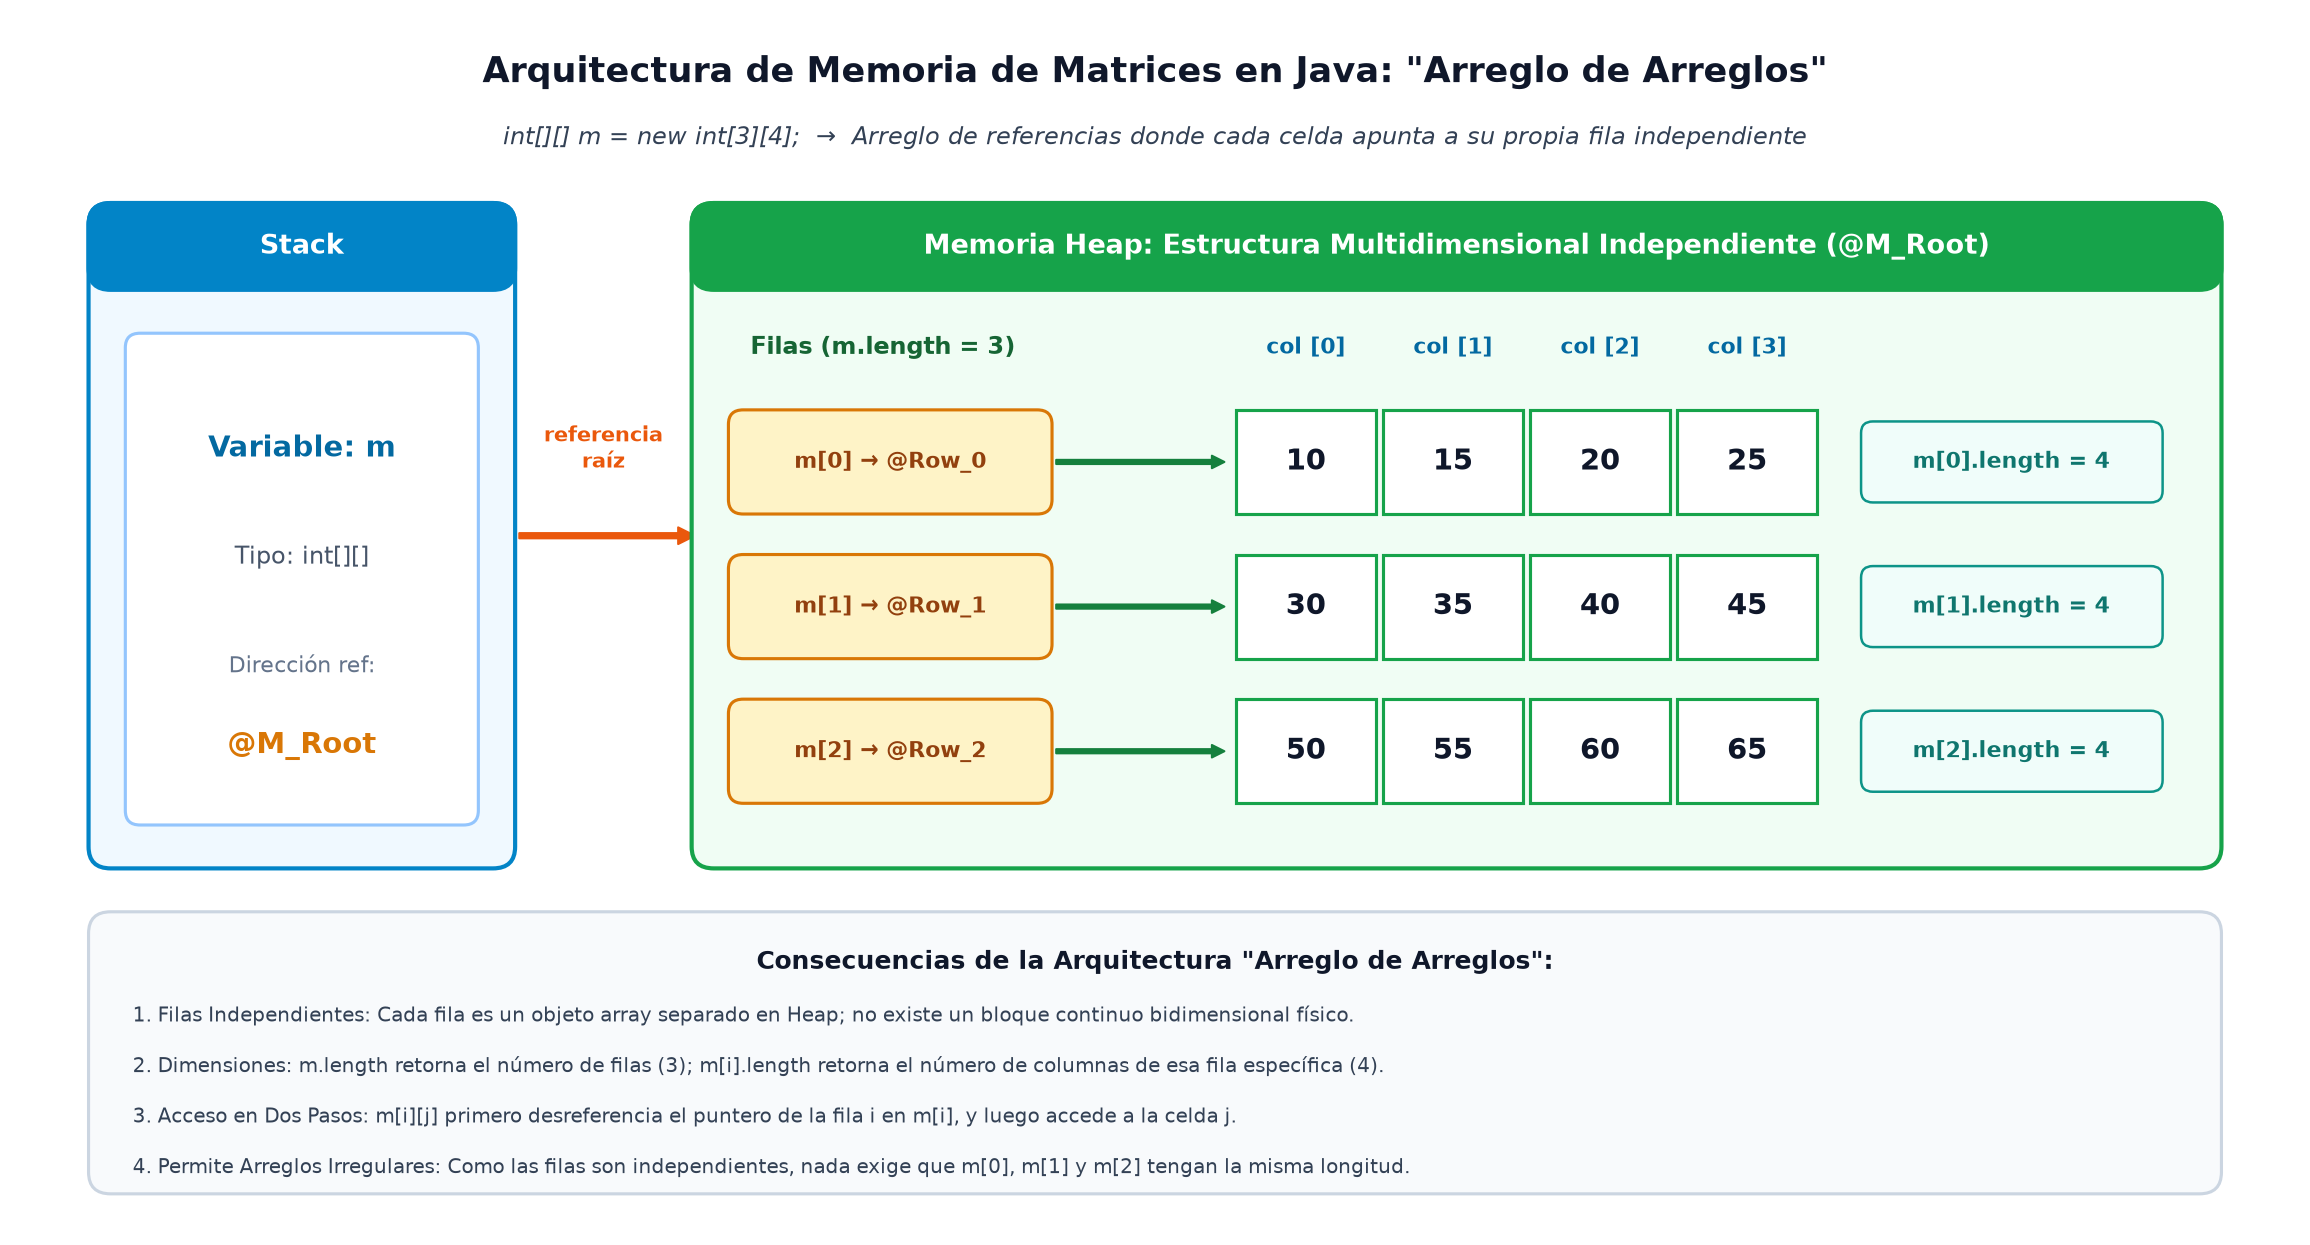
  <p><em>Figura 3: Representación en memoria de una matriz bidimensional 2D en Java. La variable en el Stack apunta a un arreglo de punteros a filas, cada uno de los cuales apunta a su propio arreglo independiente de elementos en el Heap.</em></p>
</div>



## 8. Patrones de Recorrido y Operaciones Matriciales

### Demostración 4: Matrices y Álgebra Matricial en Acción

Las operaciones matriciales clásicas requieren recorrer filas y columnas de manera estructurada:
1. **Recorrido por Filas (*Row-Major Order*):** El bucle externo recorre filas `i` y el interno columnas `j`. Es la forma natural y eficiente en memoria.
2. **Diagonal Principal:** Conjunto de celdas donde el índice de fila coincide exactamente con el índice de columna: $i == j$. Requiere que la matriz sea cuadrada ($N \times N$).
3. **Diagonal Secundaria:** Conjunto de celdas donde la suma de índices satisface: $i + j == N - 1$.
4. **Matriz Transpuesta:** Intercambia filas por columnas ($A^T[j][i] = A[i][j]$). Si la matriz original es de tamaño $M \times N$, la transpuesta será de $N \times M$.
5. **Verificación de Simetría:** Una matriz cuadrada es simétrica si $A = A^T$, es decir, si $A[i][j] == A[j][i]$ para todos los pares $(i, j)$.

<div align="center">
  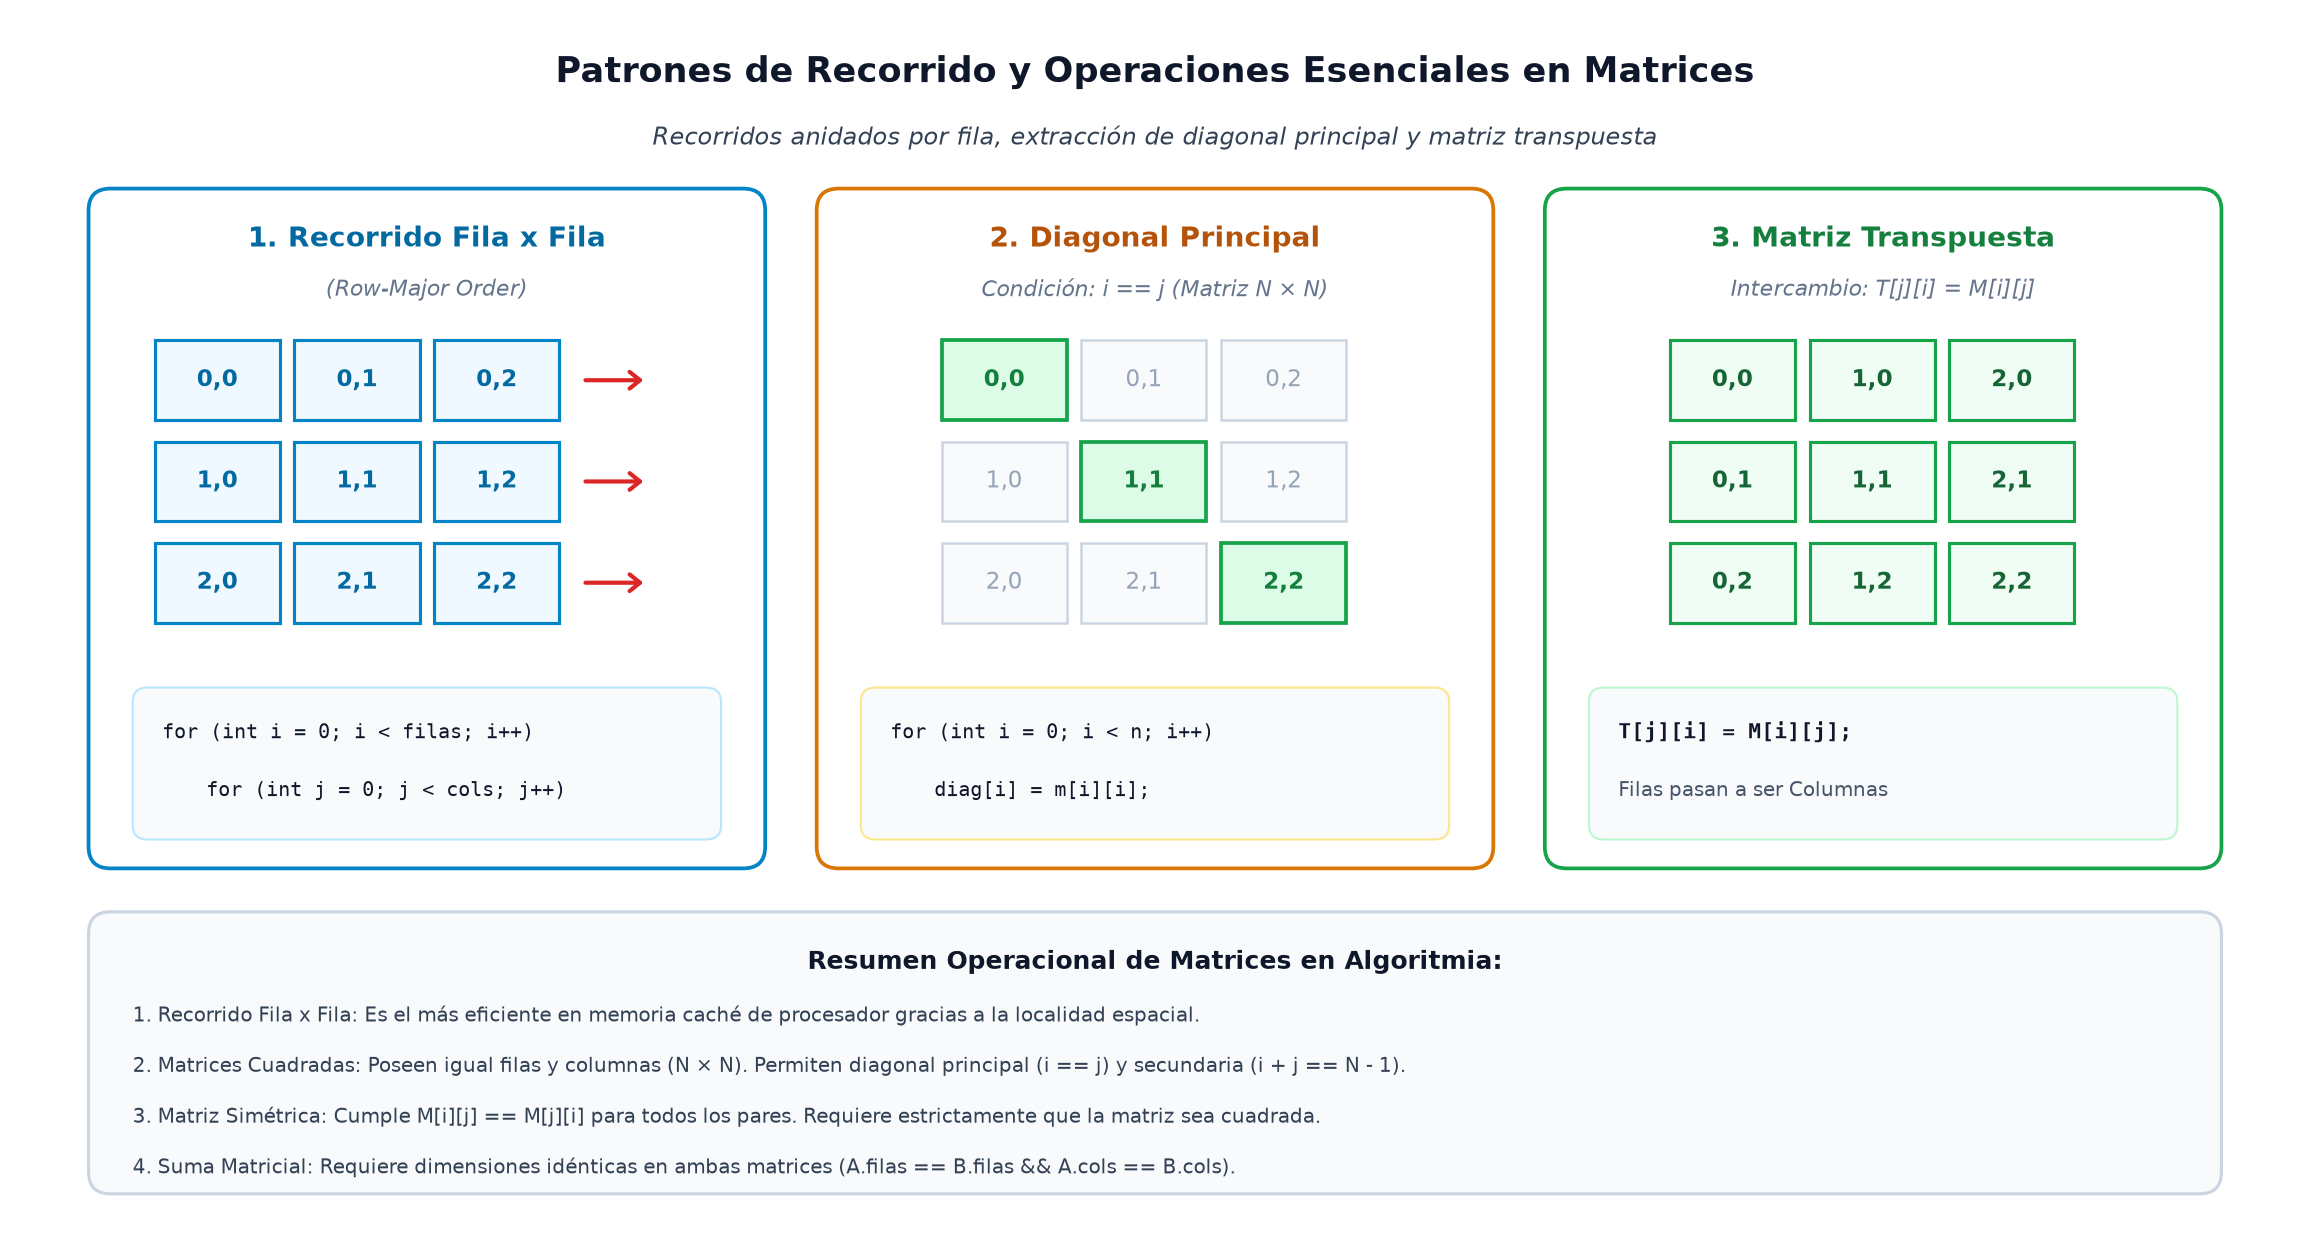
  <p><em>Figura 4: Operaciones matriciales esenciales: recorrido bidimensional por filas, identificación de la diagonal principal ($i==j$) y transposición de matrices ($M \times N \to N \times M$).</em></p>
</div>



In [7]:
%%writefile DemostracionMatrices.java
public class DemostracionMatrices {

    /**
     * Imprime una matriz con formato visual alineado.
     */
    public static void imprimirMatriz(int[][] m, String titulo) {
        System.out.println("--- " + titulo + " ---");
        for (int i = 0; i < m.length; i++) {
            System.out.print("  [ ");
            for (int j = 0; j < m[i].length; j++) {
                System.out.printf("%4d ", m[i][j]);
            }
            System.out.println("]");
        }
    }

    /**
     * Suma dos matrices rectangulares de dimensiones compatibles.
     */
    public static int[][] sumarMatrices(int[][] a, int[][] b) {
        int filas = a.length;
        int columnas = a[0].length;

        // Validación de compatibilidad
        if (b.length != filas || b[0].length != columnas) {
            throw new IllegalArgumentException("Dimensiones incompatibles para suma de matrices.");
        }

        int[][] resultado = new int[filas][columnas];
        for (int i = 0; i < filas; i++) {
            for (int j = 0; j < columnas; j++) {
                resultado[i][j] = a[i][j] + b[i][j];
            }
        }
        return resultado;
    }

    /**
     * Calcula la matriz transpuesta de dimensiones M x N -> N x M.
     */
    public static int[][] transponer(int[][] m) {
        int filas = m.length;
        int columnas = m[0].length;
        int[][] t = new int[columnas][filas];

        for (int i = 0; i < filas; i++) {
            for (int j = 0; j < columnas; j++) {
                t[j][i] = m[i][j];
            }
        }
        return t;
    }

    /**
     * Extrae e imprime las diagonales principal y secundaria de una matriz cuadrada.
     */
    public static void analizarDiagonales(int[][] m) {
        int n = m.length;
        int sumaPrincipal = 0;
        int sumaSecundaria = 0;

        System.out.print("  Diagonal Principal (i == j): [ ");
        for (int i = 0; i < n; i++) {
            System.out.print(m[i][i] + " ");
            sumaPrincipal += m[i][i];
        }
        System.out.println("] | Suma = " + sumaPrincipal);

        System.out.print("  Diagonal Secundaria (i + j == n - 1): [ ");
        for (int i = 0; i < n; i++) {
            int j = n - 1 - i;
            System.out.print(m[i][j] + " ");
            sumaSecundaria += m[i][j];
        }
        System.out.println("] | Suma = " + sumaSecundaria);
    }

    public static void main(String[] args) {
        System.out.println("=================================================");
        System.out.println("  DEMOSTRACIÓN 4: MATRICES Y ÁLGEBRA LINEAL 2D   ");
        System.out.println("=================================================\n");

        int[][] matrizA = {
            {1, 2, 3},
            {4, 5, 6},
            {7, 8, 9}
        };

        int[][] matrizB = {
            {9, 8, 7},
            {6, 5, 4},
            {3, 2, 1}
        };

        // 1. Visualización
        imprimirMatriz(matrizA, "Matriz A (3x3)");
        imprimirMatriz(matrizB, "Matriz B (3x3)");

        // 2. Suma
        int[][] suma = sumarMatrices(matrizA, matrizB);
        imprimirMatriz(suma, "Matriz Suma (A + B)");

        // 3. Análisis de Diagonales en Matriz A
        System.out.println("\n--- Análisis de Diagonales de A ---");
        analizarDiagonales(matrizA);

        // 4. Transposición
        int[][] rectangular = {
            {1, 2, 3, 4},
            {5, 6, 7, 8}
        };
        imprimirMatriz(rectangular, "Matriz Rectangular (2x4)");
        int[][] transpuesta = transponer(rectangular);
        imprimirMatriz(transpuesta, "Matriz Transpuesta (4x2)");
    }
}


Writing DemostracionMatrices.java


In [8]:
!javac -encoding UTF-8 DemostracionMatrices.java
!java DemostracionMatrices


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
  DEMOSTRACIÓN 4: MATRICES Y ÁLGEBRA LINEAL 2D   

--- Matriz A (3x3) ---
  [    1    2    3 ]
  [    4    5    6 ]
  [    7    8    9 ]
--- Matriz B (3x3) ---
  [    9    8    7 ]
  [    6    5    4 ]
  [    3    2    1 ]
--- Matriz Suma (A + B) ---
  [   10   10   10 ]
  [   10   10   10 ]
  [   10   10   10 ]

--- Análisis de Diagonales 

## 9. Arreglos Irregulares o Escalonados (*Jagged / Ragged Arrays*)

Debido a que una matriz en Java es un arreglo de referencias independientes a otros arreglos, **no existe ninguna restricción de que todas las filas deban tener la misma longitud**.

Un arreglo donde diferentes filas tienen distintas cantidades de columnas se conoce como **arreglo irregular** (*ragged* o *jagged array*).

### Declaración y Asignación en Dos Fases
Podemos dimensionar la primera dimensión dejando la segunda en blanco:
```java
// 1. Declarar e instanciar el arreglo de filas (filas = 4, columnas = sin definir aún):
int[][] irregular = new int[4][];

// 2. Instanciar individualmente cada fila con su propio tamaño:
irregular[0] = new int[2]; // Fila 0 con 2 columnas
irregular[1] = new int[4]; // Fila 1 con 4 columnas
irregular[2] = new int[1]; // Fila 2 con 1 columna
irregular[3] = new int[3]; // Fila 3 con 3 columnas
```

### Regla Fundamental de Recorrido Seguro
Al recorrer una matriz que pueda ser irregular, el límite del bucle interno **NUNCA** debe ser una constante fija. Debe consultarse siempre dinámicamente la propiedad `.length` de la fila en curso:
```java
for (int i = 0; i < irregular.length; i++) {
    for (int j = 0; j < irregular[i].length; j++) { // Correcto y seguro
        System.out.print(irregular[i][j] + " ");
    }
    System.out.println();
}
```

<div align="center">
  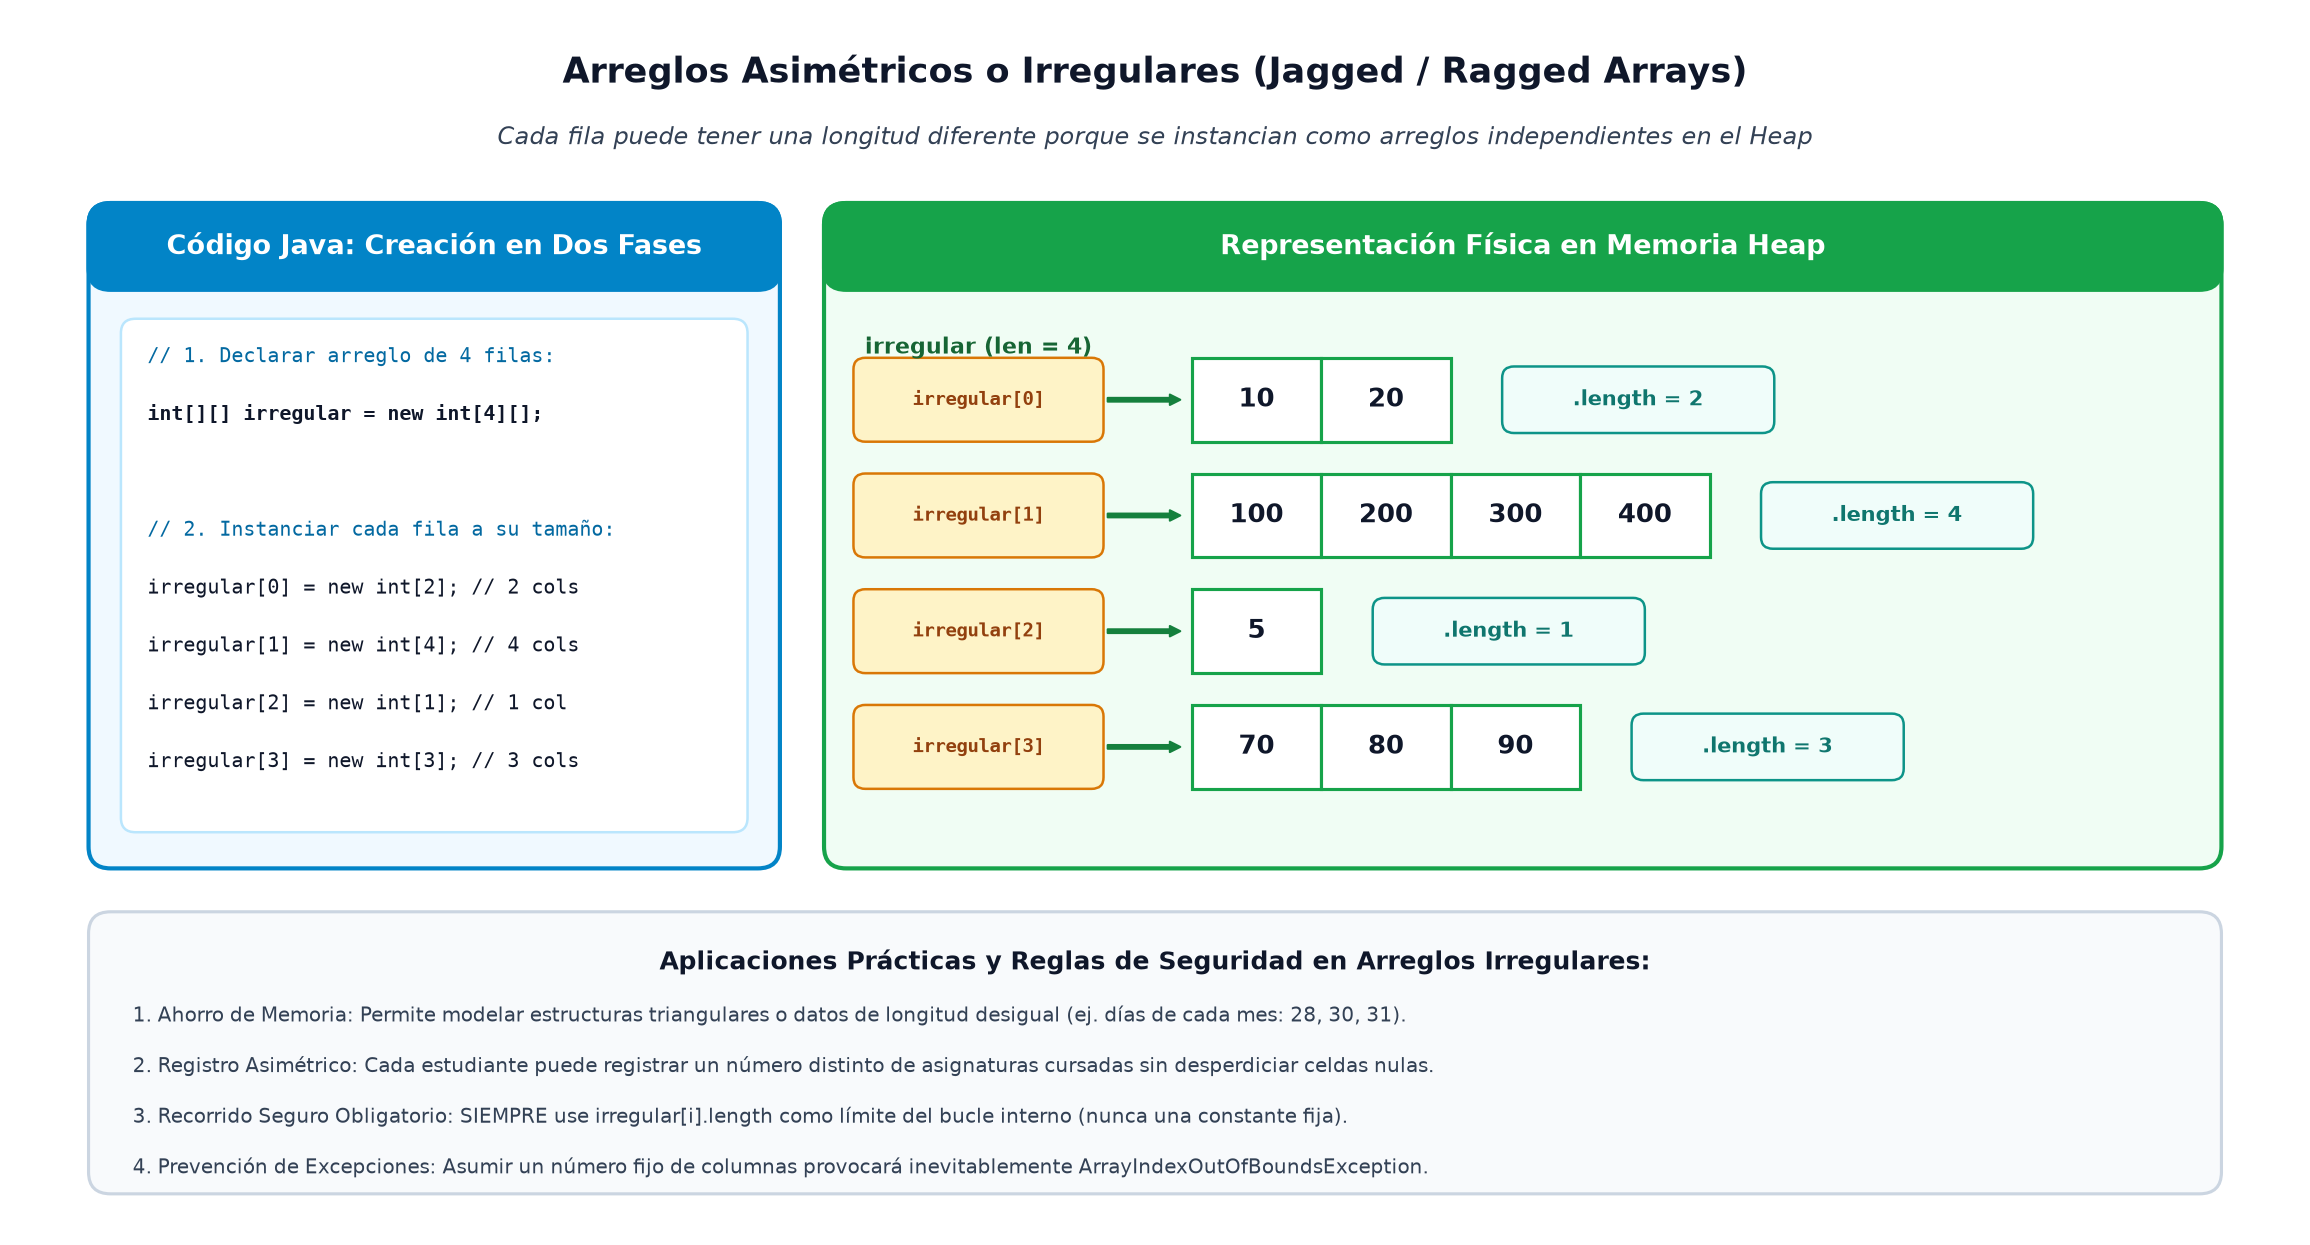
  <p><em>Figura 5: Arquitectura en memoria de un arreglo irregular (Jagged Array). El arreglo principal en el Heap mantiene referencias a filas independientes de 2, 4, 1 y 3 elementos respectivamente.</em></p>
</div>



### Demostración 5: Creación y Recorrido Seguro de Arreglos Irregulares

El siguiente ejemplo muestra la construcción de un arreglo escalonado que modela las ventas semanales de diferentes sucursales (con distinta cantidad de días de operación) y la generación del Triángulo de Pascal.



In [9]:
%%writefile DemostracionArreglosIrregulares.java
public class DemostracionArreglosIrregulares {

    /**
     * Genera el Triángulo de Pascal de N filas como un arreglo irregular.
     */
    public static int[][] generarTrianguloPascal(int n) {
        int[][] triangulo = new int[n][];

        for (int i = 0; i < n; i++) {
            // Cada fila i tiene exactamente (i + 1) columnas
            triangulo[i] = new int[i + 1];

            // Los extremos siempre son 1
            triangulo[i][0] = 1;
            triangulo[i][i] = 1;

            // Cada celda intermedia es la suma de las dos celdas superiores
            for (int j = 1; j < i; j++) {
                triangulo[i][j] = triangulo[i - 1][j - 1] + triangulo[i - 1][j];
            }
        }
        return triangulo;
    }

    public static void main(String[] args) {
        System.out.println("=================================================");
        System.out.println("  DEMOSTRACIÓN 5: ARREGLOS ESCALONADOS (JAGGED)  ");
        System.out.println("=================================================\n");

        // 1. Arreglo irregular: Registro de ventas por sucursal
        // Sucursal Norte: 3 registros, Centro: 5 registros, Sur: 2 registros
        double[][] ventas = new double[3][];
        ventas[0] = new double[]{1500.0, 2300.0, 1800.0};
        ventas[1] = new double[]{4200.0, 3100.0, 2900.0, 5100.0, 3800.0};
        ventas[2] = new double[]{950.0, 1200.0};

        System.out.println("--- 1. Ventas por Sucursal (Longitudes Asimétricas) ---");
        for (int suc = 0; suc < ventas.length; suc++) {
            double totalSucursal = 0.0;
            System.out.printf("Sucursal %d (%d registros): [ ", suc, ventas[suc].length);
            for (int d = 0; d < ventas[suc].length; d++) {
                System.out.printf("$%.0f ", ventas[suc][d]);
                totalSucursal += ventas[suc][d];
            }
            System.out.printf("] -> Total: $%.2f%n", totalSucursal);
        }

        // 2. Generación del Triángulo de Pascal (6 niveles)
        System.out.println("\n--- 2. Triángulo de Pascal (Estructura Escalonada) ---");
        int niveles = 6;
        int[][] pascal = generarTrianguloPascal(niveles);

        for (int i = 0; i < pascal.length; i++) {
            // Espaciado para formato triangular estético
            for (int k = 0; k < (niveles - i - 1) * 2; k++) {
                System.out.print(" ");
            }
            for (int j = 0; j < pascal[i].length; j++) {
                System.out.printf("%4d", pascal[i][j]);
            }
            System.out.println();
        }
    }
}


Writing DemostracionArreglosIrregulares.java


In [10]:
!javac -encoding UTF-8 DemostracionArreglosIrregulares.java
!java DemostracionArreglosIrregulares


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
  DEMOSTRACIÓN 5: ARREGLOS ESCALONADOS (JAGGED)  

--- 1. Ventas por Sucursal (Longitudes Asimétricas) ---
Sucursal 0 (3 registros): [ $1500 $2300 $1800 ] -> Total: $5600.00
Sucursal 1 (5 registros): [ $4200 $3100 $2900 $5100 $3800 ] -> Total: $19100.00
Sucursal 2 (2 registros): [ $950 $1200 ] -> Total: $2150.00

--- 2. Triángulo de Pascal 

## 10. Buenas Prácticas y Errores Frecuentes (*Pitfalls*)

### 1. Error de "Off-by-One" (Desplazamiento por uno)
El error más común en principiantes es usar `<=` en lugar de `<` al recorrer con `.length`:
```java
// INCORRECTO: Lanza ArrayIndexOutOfBoundsException en la última vuelta
for (int i = 0; i <= arr.length; i++) { ... }

// CORRECTO:
for (int i = 0; i < arr.length; i++) { ... }
```

### 2. Confundir `length` con `length()`
- `arr.length`: **Atributo** público inmutable de los arreglos (sin paréntesis).
- `str.length()`: **Método** de la clase `String` (con paréntesis).

### 3. Copia Superficial (*Shallow Copy*) vs. Copia Profunda (*Deep Copy*)
Asignar una variable de arreglo a otra (`b = a;`) **NO copia los datos**, solo copia la referencia en el *Stack*. Ambos apuntan al mismo objeto en el *Heap*. Para copiar elementos independientes:
```java
// Copia de referencia (ambos modifican el mismo arreglo):
int[] copiaFalsa = original;

// Copia superficial de elementos primitivos:
int[] copiaReal = original.clone();
// O alternativamente:
int[] copiaReal2 = Arrays.copyOf(original, original.length);
```

### 4. Intentar Redimensionar un Arreglo Existente
Un arreglo tiene tamaño fijo. Si se necesita cambiar de tamaño, se debe crear uno nuevo y migrar los datos:
```java
int[] nuevo = new int[viejo.length * 2];
System.arraycopy(viejo, 0, nuevo, 0, viejo.length);
viejo = nuevo; // viejo ahora apunta al nuevo arreglo
```

### 5. Imprimir un Arreglo con `System.out.println(arr)`
Invocar `println(arr)` ejecuta el `toString()` por defecto de `Object`, imprimiendo el identificador de clase y el hash code (por ejemplo, `[I@15db9742`). Para imprimir el contenido legible use:
```java
System.out.println(Arrays.toString(arr1D));
System.out.println(Arrays.deepToString(matriz2D));
```



## 11. Ejercicios Prácticos



### Ejercicio 1: Estadísticas y Producto Punto de Vectores

Completa los siguientes 4 métodos en `Ejercicio1Vectores.java`:
1. `calcularMedia(double[] v)`: Retorna la media aritmética $\bar{x} = \frac{1}{n}\sum_{i=0}^{n-1} v_i$. Lanza `IllegalArgumentException` si el vector es nulo o vacío.
2. `calcularDesviacionEstandar(double[] v)`: Retorna la desviación estándar poblacional $\sigma = \sqrt{\frac{1}{n}\sum_{i=0}^{n-1} (v_i - \bar{x})^2}$. Lanza `IllegalArgumentException` si es nulo o vacío.
3. `productoPunto(double[] a, double[] b)`: Retorna $\vec{a} \cdot \vec{b} = \sum_{i=0}^{n-1} a_i b_i$. Lanza `IllegalArgumentException` si son nulos o de longitudes distintas.
4. `encontrarExtremos(int[] v)`: Retorna un arreglo `int[2]` con `{minimo, maximo}` en una sola pasada $O(n)$.


In [ ]:
%%writefile Ejercicio1Vectores.java
public class Ejercicio1Vectores {

    /**
     * Calcula la media aritmética de los elementos del vector.
     */
    public static double calcularMedia(double[] v) {
        // TODO: 1. Validar que v no sea nulo ni vacío (lanzar IllegalArgumentException si lo es)
        // TODO: 2. Sumar todos los valores de v y retornar la suma dividida entre v.length
        return 0.0; // Reemplaza con tu implementación
    }

    /**
     * Calcula la desviación estándar poblacional.
     */
    public static double calcularDesviacionEstandar(double[] v) {
        // TODO: 1. Validar que v no sea nulo ni vacío (lanzar IllegalArgumentException si lo es)
        // TODO: 2. Obtener la media con calcularMedia(v)
        // TODO: 3. Sumar las diferencias al cuadrado: Math.pow(val - media, 2)
        // TODO: 4. Retornar Math.sqrt(sumaDiferencias / v.length)
        return 0.0; // Reemplaza con tu implementación
    }

    /**
     * Calcula el producto punto (escalar) entre dos vectores.
     */
    public static double productoPunto(double[] a, double[] b) {
        // TODO: 1. Validar que a y b no sean nulos y tengan exactamente la misma longitud
        // TODO: 2. Multiplicar elemento a elemento a[i] * b[i] y retornar la suma total
        return 0.0; // Reemplaza con tu implementación
    }

    /**
     * Encuentra el mínimo y máximo en una sola pasada O(n). Retorna new int[]{min, max}.
     */
    public static int[] encontrarExtremos(int[] v) {
        // TODO: 1. Validar que v no sea nulo ni vacío
        // TODO: 2. Inicializar min y max con v[0] y recorrer desde el índice 1
        return new int[]{0, 0}; // Reemplaza con tu implementación
    }

    public static void main(String[] args) {
        System.out.println("==================================================");
        System.out.println("     PRUEBAS AUTOMATIZADAS: EJERCICIO 1           ");
        System.out.println("==================================================");

        int pruebasSuperadas = 0;
        int totalPruebas = 4;

        // Prueba 1: Media
        double[] datos = {10.0, 12.0, 23.0, 23.0, 16.0, 23.0, 21.0, 16.0};
        double media = calcularMedia(datos);
        if (Math.abs(media - 18.0) < 0.01) {
            System.out.println("  [OK] calcularMedia(): " + media);
            pruebasSuperadas++;
        } else {
            System.out.printf("  [PENDIENTE] calcularMedia() -> Retornó: %.2f (Esperado: 18.00)%n", media);
        }

        // Prueba 2: Desviación estándar
        double desv = calcularDesviacionEstandar(datos);
        if (Math.abs(desv - 4.8989) < 0.01) {
            System.out.println("  [OK] calcularDesviacionEstandar(): " + desv);
            pruebasSuperadas++;
        } else {
            System.out.printf("  [PENDIENTE] calcularDesviacionEstandar() -> Retornó: %.2f (Esperado: 4.90)%n", desv);
        }

        // Prueba 3: Producto punto
        double[] v1 = {1.0, 3.0, -5.0};
        double[] v2 = {4.0, -2.0, -1.0};
        double punto = productoPunto(v1, v2);
        if (Math.abs(punto - 3.0) < 0.01) {
            System.out.println("  [OK] productoPunto(): " + punto);
            pruebasSuperadas++;
        } else {
            System.out.printf("  [PENDIENTE] productoPunto() -> Retornó: %.2f (Esperado: 3.00)%n", punto);
        }

        // Prueba 4: Extremos
        int[] enteros = {45, 12, 89, 3, 67, 99, 21};
        int[] extremos = encontrarExtremos(enteros);
        if (extremos != null && extremos.length == 2 && extremos[0] == 3 && extremos[1] == 99) {
            System.out.printf("  [OK] encontrarExtremos(): Min=%d, Max=%d%n", extremos[0], extremos[1]);
            pruebasSuperadas++;
        } else {
            System.out.println("  [PENDIENTE] encontrarExtremos() -> Retornó valores incorrectos (Esperado: Min=3, Max=99)");
        }

        System.out.println("--------------------------------------------------");
        System.out.printf("Resultado: %d de %d pruebas superadas.%n", pruebasSuperadas, totalPruebas);
        if (pruebasSuperadas == totalPruebas) {
            System.out.println(">>> ¡FELICITACIONES! Has completado el Ejercicio 1 exitosamente. <<<");
        } else {
            System.out.println(">>> ¡Sigue intentándolo! Completa los métodos marcados con // TODO para superar todas las pruebas. <<<");
        }
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio1Vectores.java
!java Ejercicio1Vectores


### Ejercicio 2: Reorganización *In-Place* de Ceros (*Move Zeroes*)

Dado un arreglo de enteros `nums`, implementa el método `moverCeros(int[] nums)` que traslade todos los ceros al final del arreglo manteniendo intacto el orden relativo de los elementos distintos de cero.

**Restricciones Obligatorias:**
1. Debes modificar el arreglo **in-place** (está prohibido crear un segundo arreglo con `new int[...]`).
2. Complejidad temporal: $O(n)$ en una sola pasada o dos pasadas sobre el mismo arreglo.
3. Complejidad espacial auxiliar: $O(1)$.


In [ ]:
%%writefile Ejercicio2MoverCeros.java
import java.util.Arrays;

public class Ejercicio2MoverCeros {

    /**
     * Mueve todos los ceros al final conservando el orden relativo de los no-ceros.
     * Modifica el arreglo in-place: O(n) tiempo y O(1) memoria auxiliar.
     */
    public static void moverCeros(int[] nums) {
        if (nums == null || nums.length <= 1) return;

        // TODO: 1. Declarar un puntero 'posInsercion = 0' para indicar dónde debe colocarse el próximo no-cero.
        // TODO: 2. Recorrer el arreglo con un bucle for. Si nums[i] != 0, copiar nums[i] en nums[posInsercion] y avanzar posInsercion++.
        // TODO: 3. Llenar de ceros todas las posiciones restantes desde posInsercion hasta el final del arreglo.
    }

    public static void main(String[] args) {
        System.out.println("==================================================");
        System.out.println("     PRUEBAS AUTOMATIZADAS: EJERCICIO 2           ");
        System.out.println("==================================================");

        int pruebasSuperadas = 0;
        int totalPruebas = 3;

        // Caso 1: Ceros intercalados
        int[] caso1 = {0, 1, 0, 3, 12};
        int[] esperado1 = {1, 3, 12, 0, 0};
        System.out.println("Caso 1 - Original: " + Arrays.toString(caso1));
        moverCeros(caso1);
        System.out.println("Caso 1 - Resultado: " + Arrays.toString(caso1));
        if (Arrays.equals(caso1, esperado1)) {
            System.out.println("  [OK] Caso 1 superado.");
            pruebasSuperadas++;
        } else {
            System.out.println("  [PENDIENTE] Caso 1 incorrecto. Esperado: " + Arrays.toString(esperado1));
        }

        // Caso 2: Ceros iniciales y finales
        int[] caso2 = {0, 0, 0, 5, 0, 8, 2, 0};
        int[] esperado2 = {5, 8, 2, 0, 0, 0, 0, 0};
        System.out.println("\nCaso 2 - Original: " + Arrays.toString(caso2));
        moverCeros(caso2);
        System.out.println("Caso 2 - Resultado: " + Arrays.toString(caso2));
        if (Arrays.equals(caso2, esperado2)) {
            System.out.println("  [OK] Caso 2 superado.");
            pruebasSuperadas++;
        } else {
            System.out.println("  [PENDIENTE] Caso 2 incorrecto. Esperado: " + Arrays.toString(esperado2));
        }

        // Caso 3: Sin ceros
        int[] caso3 = {1, 2, 3, 4};
        int[] esperado3 = {1, 2, 3, 4};
        moverCeros(caso3);
        if (Arrays.equals(caso3, esperado3)) {
            System.out.println("\n  [OK] Caso 3 superado.");
            pruebasSuperadas++;
        } else {
            System.out.println("\n  [PENDIENTE] Caso 3 incorrecto.");
        }

        System.out.println("--------------------------------------------------");
        System.out.printf("Resultado: %d de %d pruebas superadas.%n", pruebasSuperadas, totalPruebas);
        if (pruebasSuperadas == totalPruebas) {
            System.out.println(">>> ¡FELICITACIONES! Has completado el Ejercicio 2 exitosamente. <<<");
        } else {
            System.out.println(">>> ¡Sigue intentándolo! Completa la lógica in-place marcada con // TODO. <<<");
        }
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio2MoverCeros.java
!java Ejercicio2MoverCeros


### Ejercicio 3: Búsqueda Binaria Recursiva y Ordenamiento Burbuja

Completa los siguientes 2 métodos en `Ejercicio3BusquedaOrden.java`:
1. `bubbleSortConContador(int[] arr)`: Implementa el algoritmo de ordenamiento por burbuja optimizado con bandera booleana `swapped`. Debe retornar la cantidad total de **comparaciones** ejecutadas entre elementos adyacentes.
2. `busquedaBinariaRecursiva(int[] arr, int objetivo, int left, int right)`: Implementa la búsqueda binaria de forma recursiva retornando el índice donde se encuentra `objetivo`, o `-1` si no existe.


In [ ]:
%%writefile Ejercicio3BusquedaOrden.java
import java.util.Arrays;

public class Ejercicio3BusquedaOrden {

    /**
     * Ordena el arreglo in-place con BubbleSort optimizado y retorna el número de comparaciones ejecutadas.
     */
    public static int bubbleSortConContador(int[] arr) {
        int n = arr.length;
        int comparaciones = 0;

        // TODO: 1. Crear bucle externo 'i' de 0 a n - 2
        // TODO: 2. Declarar boolean huboIntercambio = false
        // TODO: 3. Crear bucle interno 'j' de 0 a n - 2 - i
        // TODO: 4. Incrementar comparaciones++ en cada iteración interna
        // TODO: 5. Si arr[j] > arr[j + 1], intercambiar y marcar huboIntercambio = true
        // TODO: 6. Si al finalizar el bucle interno !huboIntercambio, romper con break

        return comparaciones; // Retorna la cantidad de comparaciones
    }

    /**
     * Búsqueda binaria recursiva sobre un arreglo ordenado.
     */
    public static int busquedaBinariaRecursiva(int[] arr, int objetivo, int left, int right) {
        // TODO: 1. Caso base: si left > right, el elemento no existe (retornar -1)
        // TODO: 2. Calcular mid = left + (right - left) / 2
        // TODO: 3. Si arr[mid] == objetivo, retornar mid
        // TODO: 4. Si arr[mid] > objetivo, llamada recursiva a la mitad izquierda (right = mid - 1)
        // TODO: 5. Si arr[mid] < objetivo, llamada recursiva a la mitad derecha (left = mid + 1)
        return -1; // Reemplaza con tu implementación
    }

    public static void main(String[] args) {
        System.out.println("==================================================");
        System.out.println("     PRUEBAS AUTOMATIZADAS: EJERCICIO 3           ");
        System.out.println("==================================================");

        int pruebasSuperadas = 0;
        int totalPruebas = 3;

        // Prueba 1: Parada temprana en arreglo ya ordenado
        int[] yaOrdenado = {1, 2, 3, 4, 5, 6};
        int compYaOrdenado = bubbleSortConContador(yaOrdenado);
        if (compYaOrdenado == 5) {
            System.out.println("  [OK] BubbleSort optimizado detectó arreglo ordenado en 5 comparaciones.");
            pruebasSuperadas++;
        } else {
            System.out.printf("  [PENDIENTE] BubbleSort en ordenado realizó: %d comparaciones (Esperado: 5)%n", compYaOrdenado);
        }

        // Prueba 2: Ordenamiento de arreglo desordenado
        int[] datos = {50, 20, 40, 10, 30};
        int[] esperado = {10, 20, 30, 40, 50};
        bubbleSortConContador(datos);
        if (Arrays.equals(datos, esperado)) {
            System.out.println("  [OK] BubbleSort ordenó correctamente: " + Arrays.toString(datos));
            pruebasSuperadas++;
        } else {
            System.out.println("  [PENDIENTE] BubbleSort no ordenó adecuadamente. Resultado: " + Arrays.toString(datos));
        }

        // Prueba 3: Búsqueda Binaria Recursiva
        int idx40 = busquedaBinariaRecursiva(datos, 40, 0, datos.length - 1);
        int idx99 = busquedaBinariaRecursiva(datos, 99, 0, datos.length - 1);
        if (idx40 == 3 && idx99 == -1) {
            System.out.printf("  [OK] Búsqueda Binaria: Elemento 40 en índice %d | Elemento 99 en índice %d%n", idx40, idx99);
            pruebasSuperadas++;
        } else {
            System.out.printf("  [PENDIENTE] Búsqueda Binaria falló -> 40: %d (esp: 3), 99: %d (esp: -1)%n", idx40, idx99);
        }

        System.out.println("--------------------------------------------------");
        System.out.printf("Resultado: %d de %d pruebas superadas.%n", pruebasSuperadas, totalPruebas);
        if (pruebasSuperadas == totalPruebas) {
            System.out.println(">>> ¡FELICITACIONES! Has completado el Ejercicio 3 exitosamente. <<<");
        } else {
            System.out.println(">>> ¡Sigue intentándolo! Completa los métodos marcados con // TODO. <<<");
        }
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio3BusquedaOrden.java
!java Ejercicio3BusquedaOrden


### Ejercicio 4: Álgebra Matricial y Verificación de Simetría

Completa los siguientes 3 métodos en `Ejercicio4Matrices.java`:
1. `calcularTraza(int[][] m)`: Retorna la suma de los elementos de la diagonal principal ($i == j$). Si la matriz no es cuadrada o es nula/vacía, lanza `IllegalArgumentException`.
2. `multiplicarMatrices(int[][] a, int[][] b)`: Multiplica dos matrices $A_{m \times k} \times B_{k \times n} = C_{m \times n}$. Si las dimensiones son incompatibles ($A.\text{cols} \neq B.\text{filas}$), lanza `IllegalArgumentException`.
3. `esSimetrica(int[][] m)`: Retorna `true` si la matriz es cuadrada y simétrica ($m[i][j] == m[j][i]$ para todo $i, j$).


In [ ]:
%%writefile Ejercicio4Matrices.java
public class Ejercicio4Matrices {

    /**
     * Calcula la traza de una matriz cuadrada (suma de la diagonal principal).
     */
    public static int calcularTraza(int[][] m) {
        // TODO: 1. Validar que m no sea nulo, ni vacío, y que sea estrictamente cuadrada (filas == columnas)
        // TODO: 2. Sumar los elementos m[i][i] y retornar el resultado
        return 0; // Reemplaza con tu implementación
    }

    /**
     * Multiplica dos matrices A (m x k) y B (k x n) resultando en C (m x n).
     */
    public static int[][] multiplicarMatrices(int[][] a, int[][] b) {
        // TODO: 1. Obtener dimensiones filasA, colsA, filasB, colsB
        // TODO: 2. Validar que colsA == filasB (lanzar IllegalArgumentException si no coinciden)
        // TODO: 3. Crear matriz resultado C = new int[filasA][colsB]
        // TODO: 4. Implementar triple bucle anidado: C[i][j] += a[i][k] * b[k][j]
        return new int[0][0]; // Reemplaza con tu implementación
    }

    /**
     * Determina si una matriz cuadrada es simétrica (m[i][j] == m[j][i]).
     */
    public static boolean esSimetrica(int[][] m) {
        // TODO: 1. Validar que m no sea nulo, ni vacío, y que sea cuadrada
        // TODO: 2. Comparar m[i][j] con m[j][i] para todos los pares donde i < j. Si difieren, retornar false.
        // TODO: 3. Si ninguna pareja difiere, retornar true
        return false; // Reemplaza con tu implementación
    }

    public static void main(String[] args) {
        System.out.println("==================================================");
        System.out.println("     PRUEBAS AUTOMATIZADAS: EJERCICIO 4           ");
        System.out.println("==================================================");

        int pruebasSuperadas = 0;
        int totalPruebas = 3;

        // Prueba 1: Traza
        int[][] cuad = {
            {5, -1, 3},
            {2,  8, 4},
            {1,  0, 2}
        };
        int traza = calcularTraza(cuad);
        if (traza == 15) {
            System.out.println("  [OK] calcularTraza(): " + traza + " (Esperado: 15)");
            pruebasSuperadas++;
        } else {
            System.out.printf("  [PENDIENTE] calcularTraza() retornó: %d (Esperado: 15)%n", traza);
        }

        // Prueba 2: Simetría
        int[][] simetrica = {
            {1, 7, 3},
            {7, 4, -5},
            {3, -5, 6}
        };
        boolean esSim = esSimetrica(simetrica);
        boolean noEsSim = esSimetrica(cuad);
        if (esSim && !noEsSim) {
            System.out.println("  [OK] esSimetrica(): Identificó correctamente matrices simétricas y no simétricas.");
            pruebasSuperadas++;
        } else {
            System.out.printf("  [PENDIENTE] esSimetrica() falló -> simetrica=%b (esp: true), cuad=%b (esp: false)%n", esSim, noEsSim);
        }

        // Prueba 3: Multiplicación
        int[][] m1 = {{1, 2}, {3, 4}};
        int[][] m2 = {{2, 0}, {1, 2}};
        int[][] prod = multiplicarMatrices(m1, m2);
        boolean prodOk = prod.length == 2 && prod[0].length == 2 &&
                         prod[0][0] == 4 && prod[0][1] == 4 &&
                         prod[1][0] == 10 && prod[1][1] == 8;
        if (prodOk) {
            System.out.println("  [OK] multiplicarMatrices(): Producto matricial 2x2 calculado con precisión.");
            pruebasSuperadas++;
        } else {
            System.out.println("  [PENDIENTE] multiplicarMatrices() retornó resultado incorrecto.");
        }

        System.out.println("--------------------------------------------------");
        System.out.printf("Resultado: %d de %d pruebas superadas.%n", pruebasSuperadas, totalPruebas);
        if (pruebasSuperadas == totalPruebas) {
            System.out.println(">>> ¡FELICITACIONES! Has completado el Ejercicio 4 exitosamente. <<<");
        } else {
            System.out.println(">>> ¡Sigue intentándolo! Completa los métodos matriciales marcados con // TODO. <<<");
        }
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio4Matrices.java
!java Ejercicio4Matrices


### Ejercicio 5: Verificador de Cuadrados Mágicos (*Magic Squares*)

Un **cuadrado mágico** de orden $N$ es una matriz cuadrada $N \times N$ que contiene exactamente todos los números enteros del $1$ al $N^2$ sin repetición, tal que la suma de los elementos en cada fila, en cada columna y en ambas diagonales principales es exactamente igual a la constante mágica:
$$M = \frac{N(N^2 + 1)}{2}$$

Implementa el método:
```java
public static boolean esCuadradoMagico(int[][] matriz)
```
que retorne `true` únicamente si se cumplen todas las condiciones, y `false` en cualquier otro caso.


In [ ]:
%%writefile Ejercicio5CuadradoMagico.java
public class Ejercicio5CuadradoMagico {

    /**
     * Valida si una matriz es un cuadrado mágico perfecto de orden N x N.
     */
    public static boolean esCuadradoMagico(int[][] matriz) {
        if (matriz == null || matriz.length == 0) return false;

        int n = matriz.length;

        // TODO: 1. Validar que la matriz sea estrictamente cuadrada (cada fila matriz[i].length == n)
        // TODO: 2. Calcular la constante mágica teórica: int M = n * (n * n + 1) / 2;
        // TODO: 3. Verificar que contenga exactamente los números del 1 al n^2 sin duplicados (usar boolean[] visto = new boolean[n*n + 1])
        // TODO: 4. Verificar que la suma de cada fila sea igual a M
        // TODO: 5. Verificar que la suma de cada columna sea igual a M
        // TODO: 6. Verificar que la suma de la diagonal principal (i == j) y de la secundaria (i + j == n - 1) sean ambas iguales a M

        return false; // Reemplaza con tu implementación
    }

    public static void main(String[] args) {
        System.out.println("==================================================");
        System.out.println("     PRUEBAS AUTOMATIZADAS: EJERCICIO 5           ");
        System.out.println("==================================================");

        int pruebasSuperadas = 0;
        int totalPruebas = 4;

        // Caso 1: Cuadrado mágico válido de orden 3 (Constante Mágica = 15)
        int[][] magico3x3 = {
            {8, 1, 6},
            {3, 5, 7},
            {4, 9, 2}
        };

        // Caso 2: Cuadrado mágico de Durero de orden 4 (Constante Mágica = 34)
        int[][] magico4x4 = {
            {16,  2,  3, 13},
            { 5, 11, 10,  8},
            { 9,  7,  6, 12},
            { 4, 14, 15,  1}
        };

        // Caso 3: Matriz no cuadrada
        int[][] noCuadrada = {
            {1, 2, 3},
            {4, 5, 6}
        };

        // Caso 4: Matriz con números repetidos
        int[][] repetidos = {
            {2, 2, 2},
            {2, 2, 2},
            {2, 2, 2}
        };

        boolean test1 = esCuadradoMagico(magico3x3);
        boolean test2 = esCuadradoMagico(magico4x4);
        boolean test3 = !esCuadradoMagico(noCuadrada);
        boolean test4 = !esCuadradoMagico(repetidos);

        if (test1) {
            System.out.println("  [OK] Cuadrado Mágico 3x3 validado como verdadero.");
            pruebasSuperadas++;
        } else {
            System.out.println("  [PENDIENTE] Cuadrado Mágico 3x3 no fue validado correctamente.");
        }

        if (test2) {
            System.out.println("  [OK] Cuadrado Mágico 4x4 validado como verdadero.");
            pruebasSuperadas++;
        } else {
            System.out.println("  [PENDIENTE] Cuadrado Mágico 4x4 no fue validado correctamente.");
        }

        if (test3) {
            System.out.println("  [OK] Rechazó correctamente matriz no cuadrada.");
            pruebasSuperadas++;
        } else {
            System.out.println("  [PENDIENTE] No rechazó matriz no cuadrada.");
        }

        if (test4) {
            System.out.println("  [OK] Rechazó correctamente matriz con números repetidos.");
            pruebasSuperadas++;
        } else {
            System.out.println("  [PENDIENTE] No rechazó matriz con números duplicados.");
        }

        System.out.println("--------------------------------------------------");
        System.out.printf("Resultado: %d de %d pruebas superadas.%n", pruebasSuperadas, totalPruebas);
        if (pruebasSuperadas == totalPruebas) {
            System.out.println(">>> ¡FELICITACIONES! Has completado el Ejercicio 5 exitosamente. <<<");
        } else {
            System.out.println(">>> ¡Sigue intentándolo! Completa las validaciones marcadas con // TODO. <<<");
        }
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio5CuadradoMagico.java
!java Ejercicio5CuadradoMagico


## 12. Bibliografía y Referencias

1. **Streib, J. T., & Soma, T. (2014).** *Guide to Java: A Concise Introduction to Programming*. Springer London.
   - Capítulo 7: *Arrays* (pp. 129–158). Cobertura exhaustiva de vectores unidimensionales, matrices bidimensionales, inicialización, algoritmos de búsqueda y ordenamiento.
2. **Barnes, D. J., & Kölling, M. (2017).** *Programación orientada a objetos con Java usando BlueJ*. 6.ª edición, Pearson Educación.
   - Enfoque pedagógico en modelado de colecciones de objetos, gestión de memoria y encapsulamiento.
3. **Deitel, P., & Deitel, H. (2018).** *Java How to Program, Early Objects*. 11.ª edición, Pearson.
   - Capítulo 7: *Arrays and ArrayLists*. Análisis detallado de paso de arreglos por referencia a métodos y manipulación matricial.
4. **Oracle Corporation.** *The Java Tutorials: Arrays*.
   - Documentación oficial de la especificación del lenguaje Java (JLS §10 - Arrays).

